# Measuring Eddy Currents with NMR Probe - INV LAPLACE FITTING PARAMETERS

The NMR probe is made to measure the eddy currents in different places within the imaging volume.

### Imports

In [1]:
from matipo import SEQUENCE_DIR, GLOBALS_DIR
from matipo.sequence import Sequence
from matipo.util.autophase import autophase
from matipo.util.decimation import decimate
from matipo.util.fft import fft_reconstruction
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from matipo.util.pulseshape import calc_soft_pulse
from matipo.util.fft import fft_reconstruction
from matipo.util.fft import get_freq_spectrum
# progress_handler for Sequence.run() that simply prints the progress
def print_progress(p, l):
    print(p, '/', l)

In [2]:
import panel as pn
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import os
from scipy.optimize import curve_fit

### Functions

In [3]:

def get_yaml_info(info_name = None, file = None):
    """
    Retrieves the infomation stored in a yaml file and returns it as a dictionary (val).

    Inputs:
        info_name (str): name of the yaml file to retrieve info from - can end with or without .yaml and work
            but needs to be a yaml file.
        file (str): name of the filepath to get the the info_name.yaml with the information in 
            (should be stored in a globals file on your kahu workspace)
        
    Output:
        val (dictionary): dictionary of the information stored in the yaml file asked to be retrieved from 
    
    """
    if file == None:
        file = "C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/globals"

    if info_name == None:
        info_name = 'shims'
    try:
        if ".yaml" in info_name:
            with open(f"{file}/{info_name}", "r") as f:
                val = yaml.safe_load(f) # list
            return val
        else:
            with open(f"{file}/{info_name}.yaml", "r") as f:
                val = yaml.safe_load(f) # list
            return val
    except Exception:
        print(f"The file: {info_name} does not exist in {file}.")

def get_exp(file = "C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/globals/", b0 = "n"):
    """
    """
    if b0 =="y":
       info_name = "eddy_B0new.yaml" 
    else:
        info_name = "eddy_Enew.yaml"
    print(f"{file}{info_name}")
    try:
        
        with open(f"{file}{info_name}", "r") as f:
            val = yaml.safe_load(f)
    
    except Exception as e:
        ValueError(f"{file}/eddy_B0 or eddy_E doesnt exist")
        
    if isinstance(val, dict):
        return val
    
    params_dict = {}
    for item in val:
        params_dict.update(item)
    
    return params_dict
    
def n_exp_log(t, *params):
    """
    params = (A0, A1, ..., An, logtau1, ..., logtaun)
    A0 is the offset; taus are parameterized as ln(tau).
    """
    n = (len(params) - 1) // 2
    A0 = params[0]
    amps = params[1:1 + n]
    logtaus = params[1 + n:]
    y = np.full_like(t, A0, dtype=float)
    for A, logtau in zip(amps, logtaus):
        y += A * np.exp(-t / np.exp(logtau))
    return y
    
# p_dict = {}

# axis = "y"
# for axis in ["x", "y", "z"]:
#     axis = axis.upper()
#     params_dict = get_exp(b0 = 'n')
#     print(params_dict[axis])
#     params = params_dict[axis]
#     print(params)
    
#     p = [
#        params["A0"],
#         params["A1"],
#         params["A2"],
#         params["A3"],
#         params["A4"],
#         np.log(params["tau1"]),
#        np.log(params["tau2"]),
#         np.log(params["tau3"]),
#         np.log(params["tau4"])
#     ]
    
    
#     E_fit = n_exp_log(df_freq["times (s)"], 0, *p[1:]) # calculate fit with A0 offset
    
#     plt.plot(E_fit, label = axis)
#     p_dict[axis] = E_fit

# plt.legend()

In [4]:
vals = get_yaml_info(info_name = "hardpulse_90_tx0.yaml", file = None)

In [5]:
vals

{'a_90': 0.45, 't_90': 0.0006}

### Run Sequence 

The seq consists of a long gradient pulse which has and FID then is turned off. RF pulses and acquisitions are staggered after this to obtain the eddy current effects over time and measure them. The frequency of these acquisitions is collected and is plotted over time (should be an exp decay). The frequency info shows the eddy currents and then we use the RMS of the raw signal to check that the flip angle used leads to steady-state behaviour. The RMS is plotted against the time and should be non-zero to show that there is signal being acquired.

Notes:
- n_pulses does not include the gradient calibration pulse (just how many are in the eddy current acquisistion)

In [6]:
g_list = np.linspace(-0.2, 0.2, 11)
print(g_list)

[-0.2  -0.16 -0.12 -0.08 -0.04  0.    0.04  0.08  0.12  0.16  0.2 ]


g_list: [-0.2  -0.16 -0.12 -0.08 -0.04  0.    0.04  0.08  0.12  0.16  0.2 ]
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.4,  0. ,  0. ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


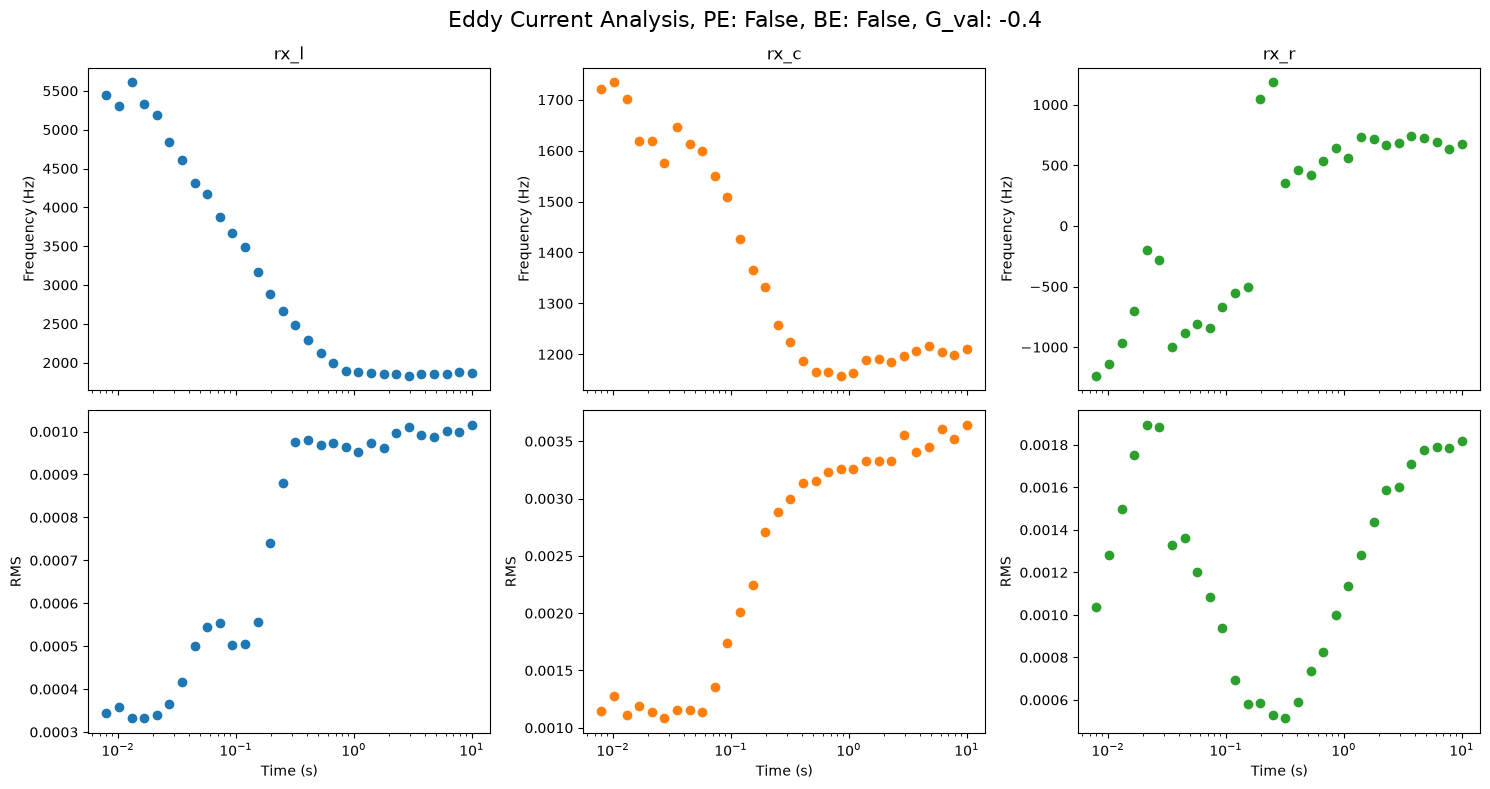

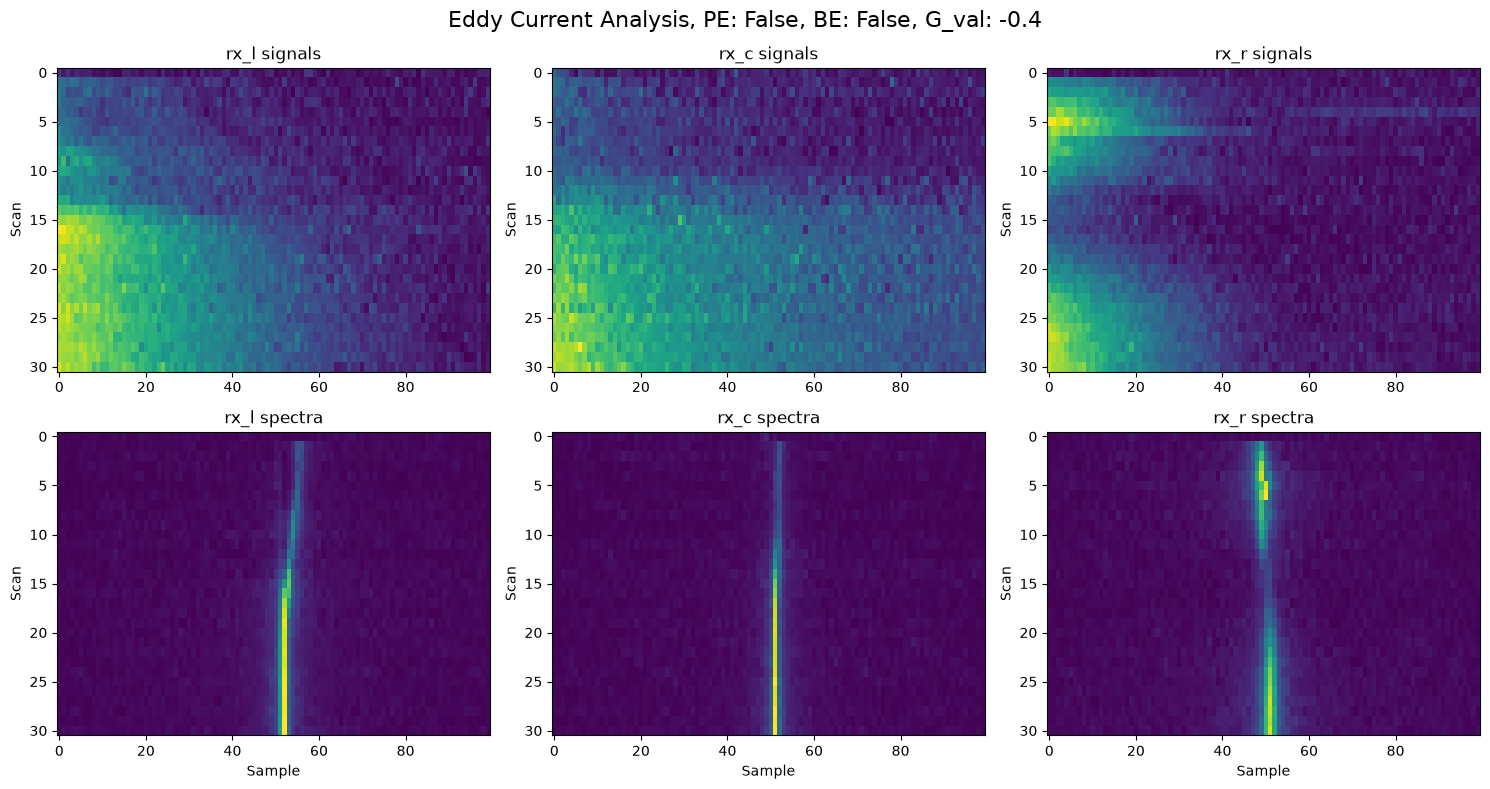

-487151.424287856
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.32,  0.  ,  0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


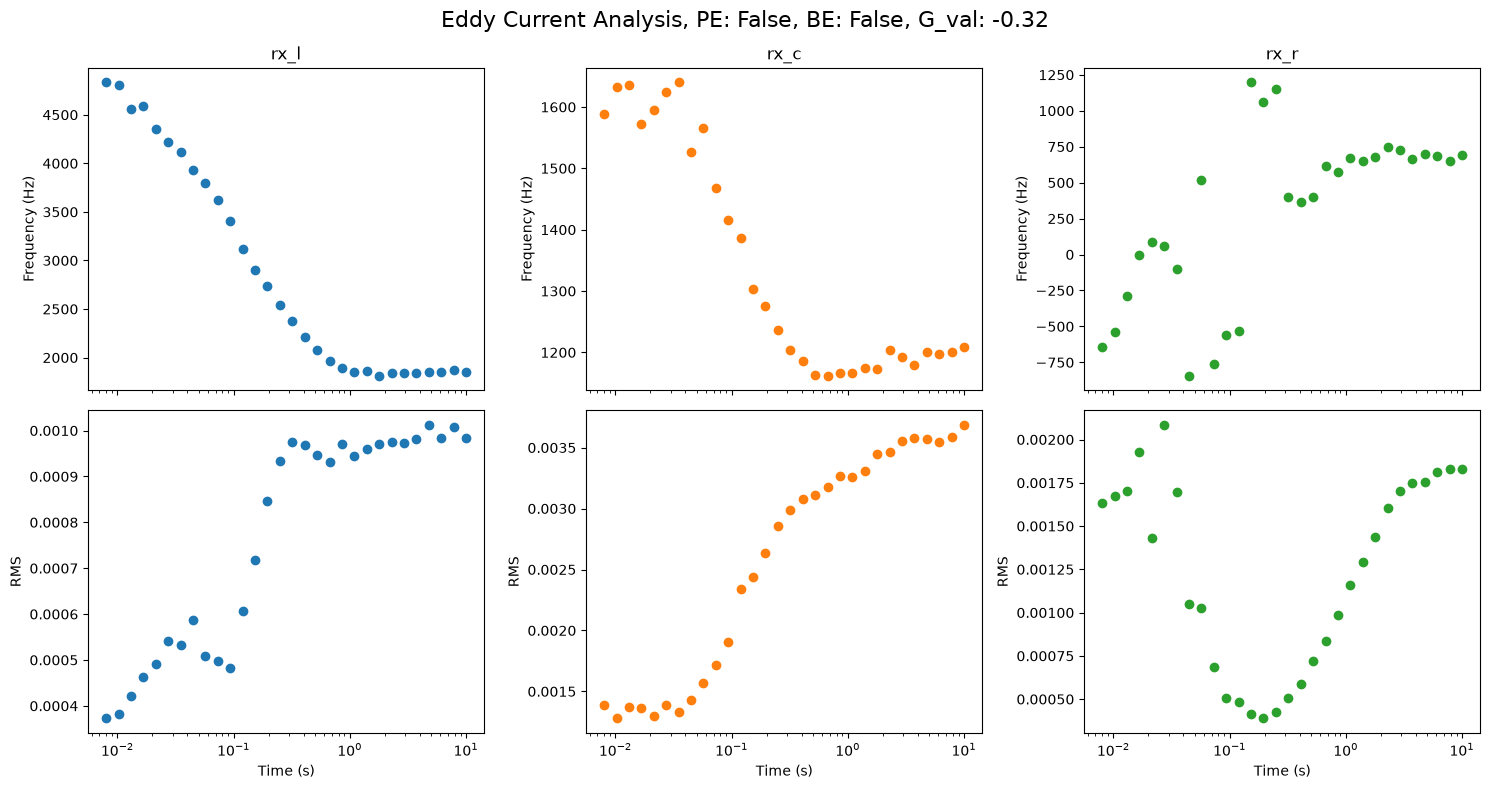

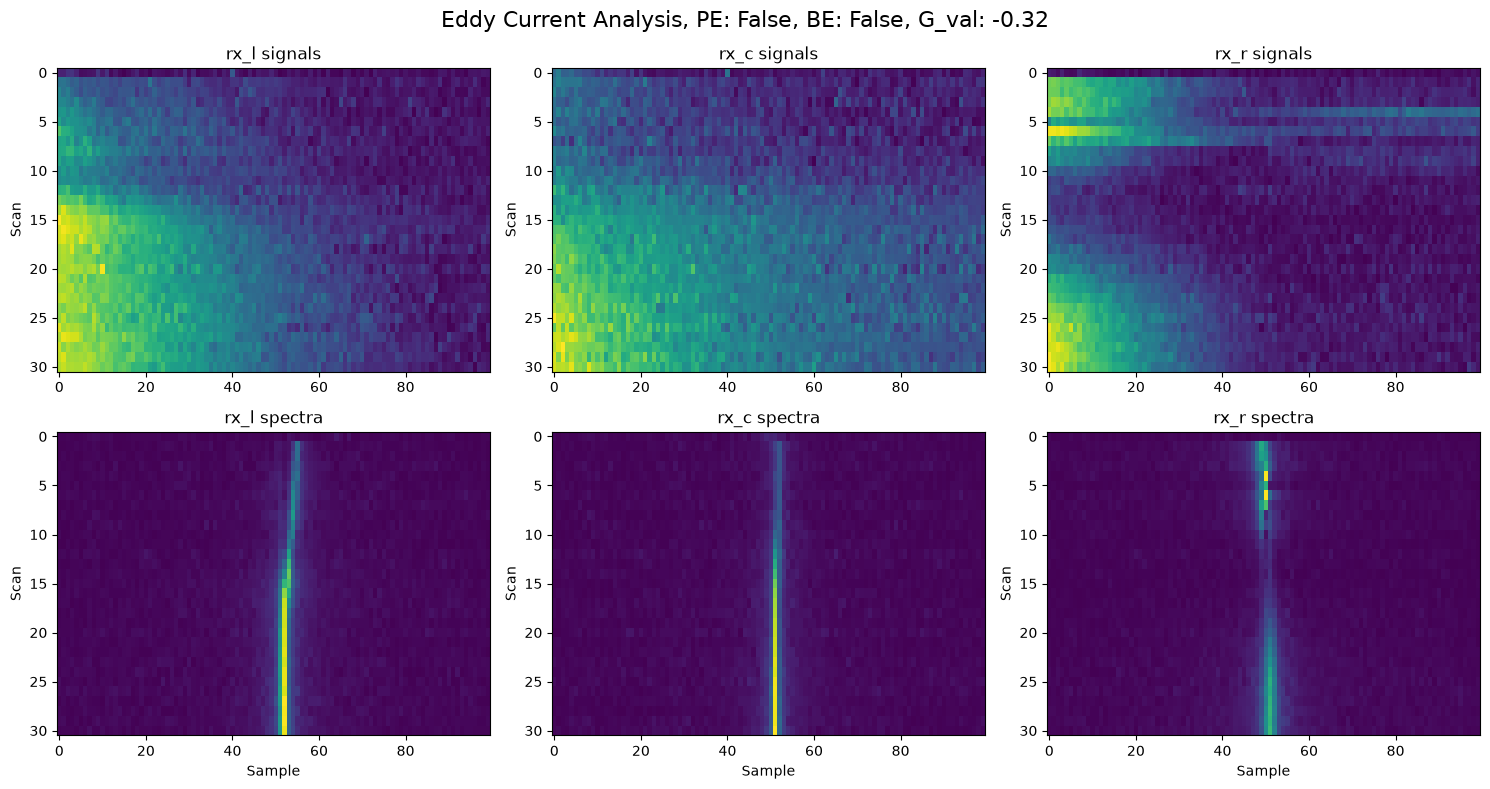

-109405.2973513243
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.24,  0.  ,  0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


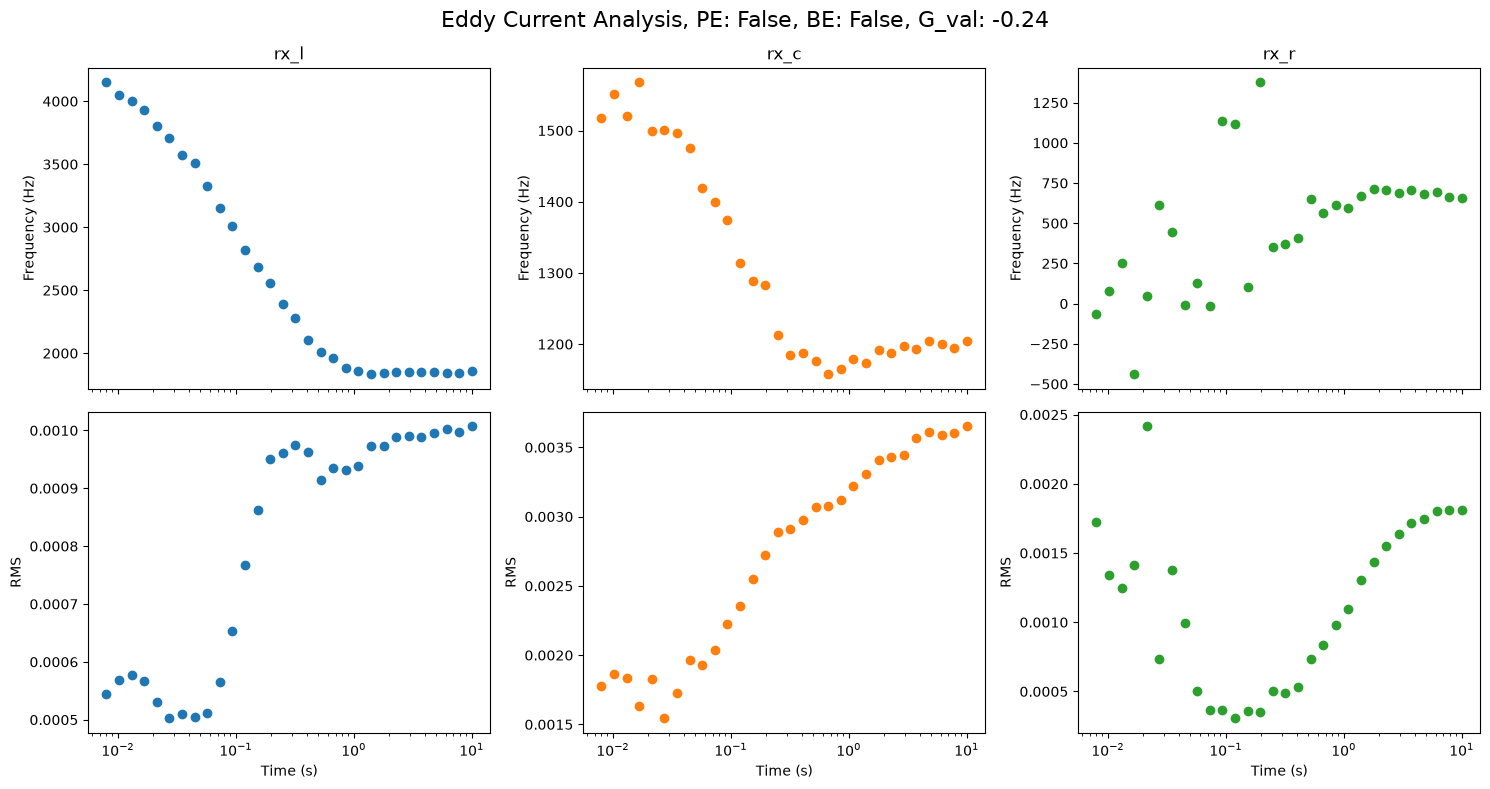

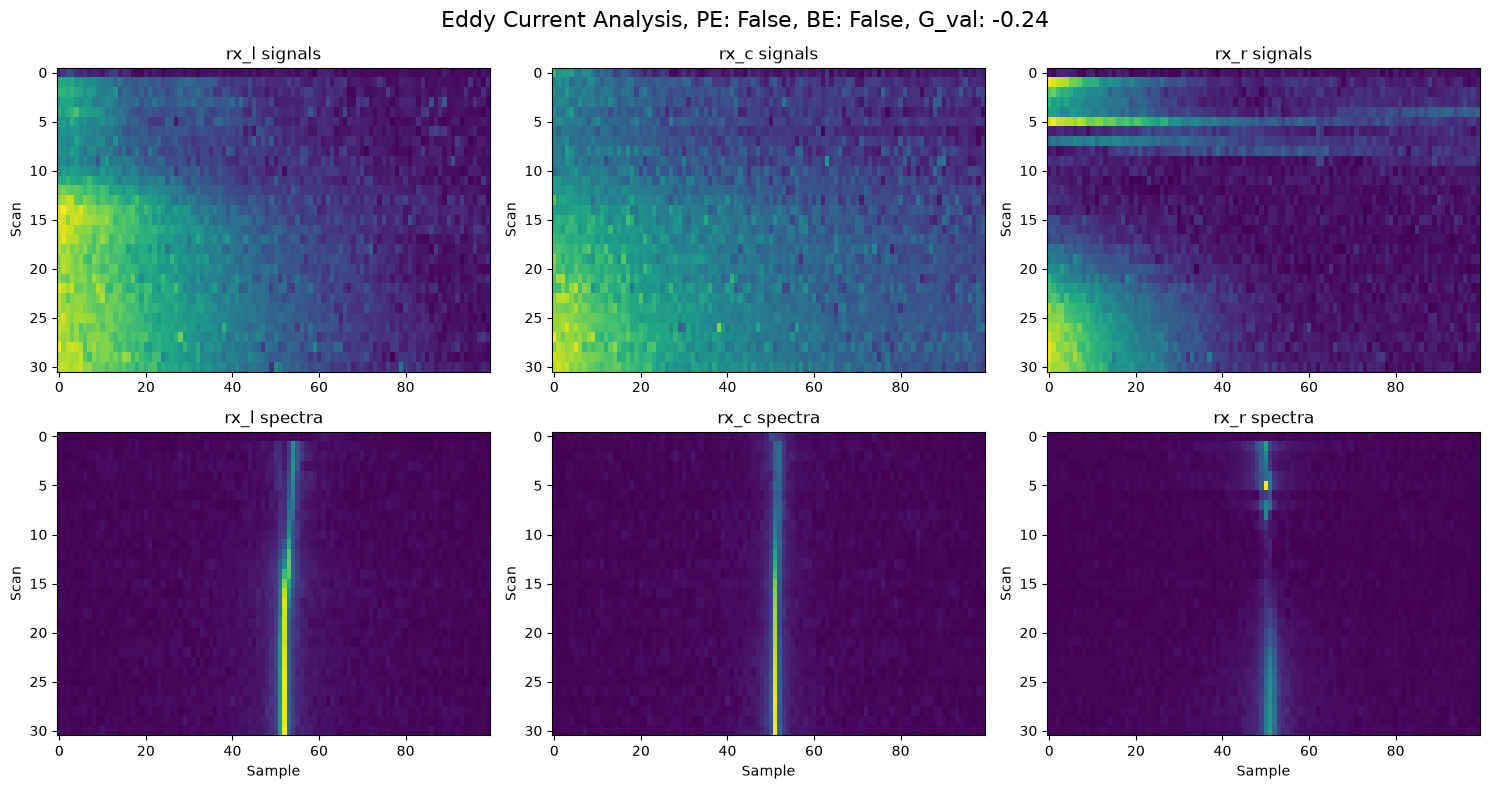

124342.82858570712
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.16,  0.  ,  0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


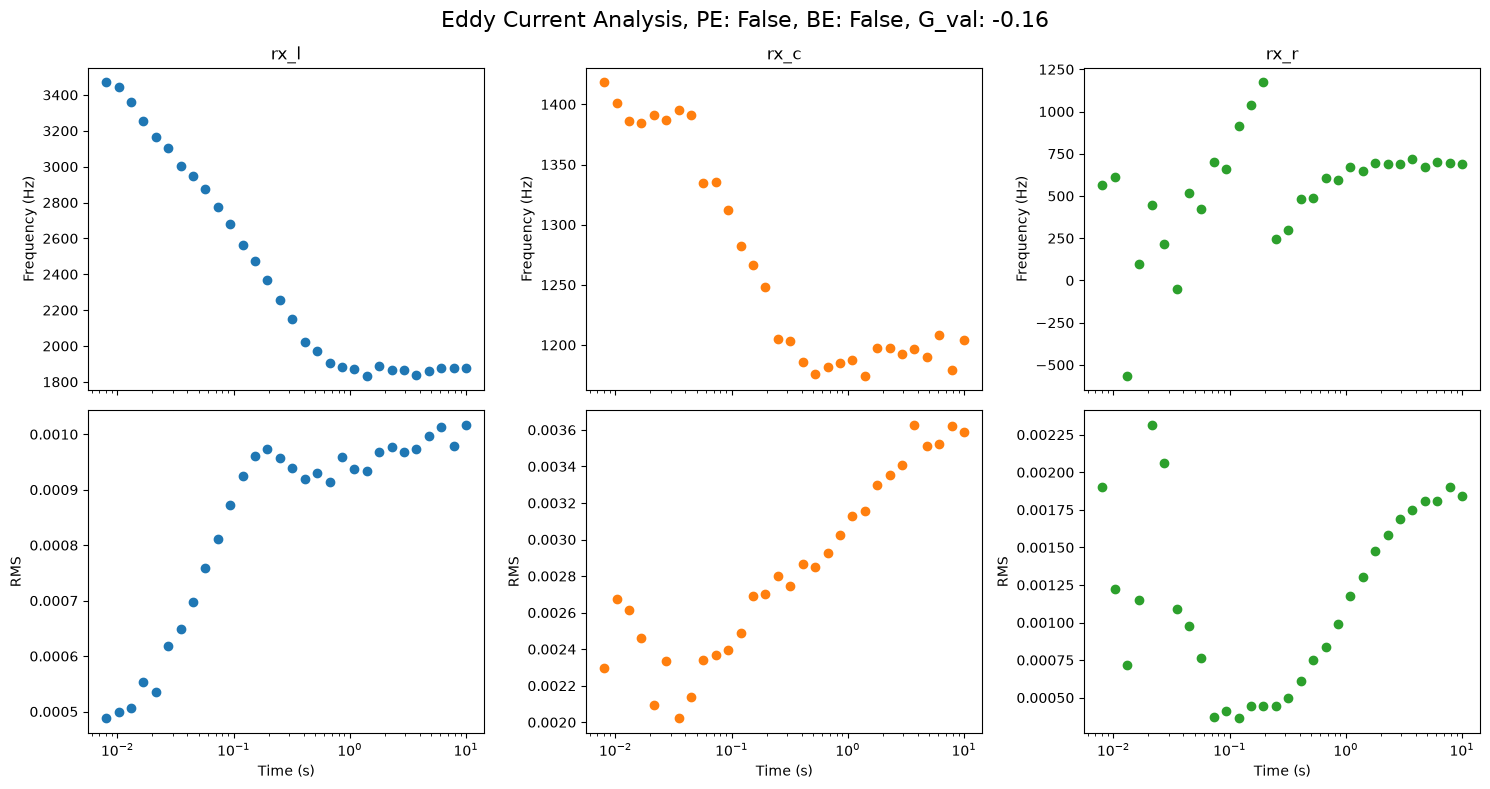

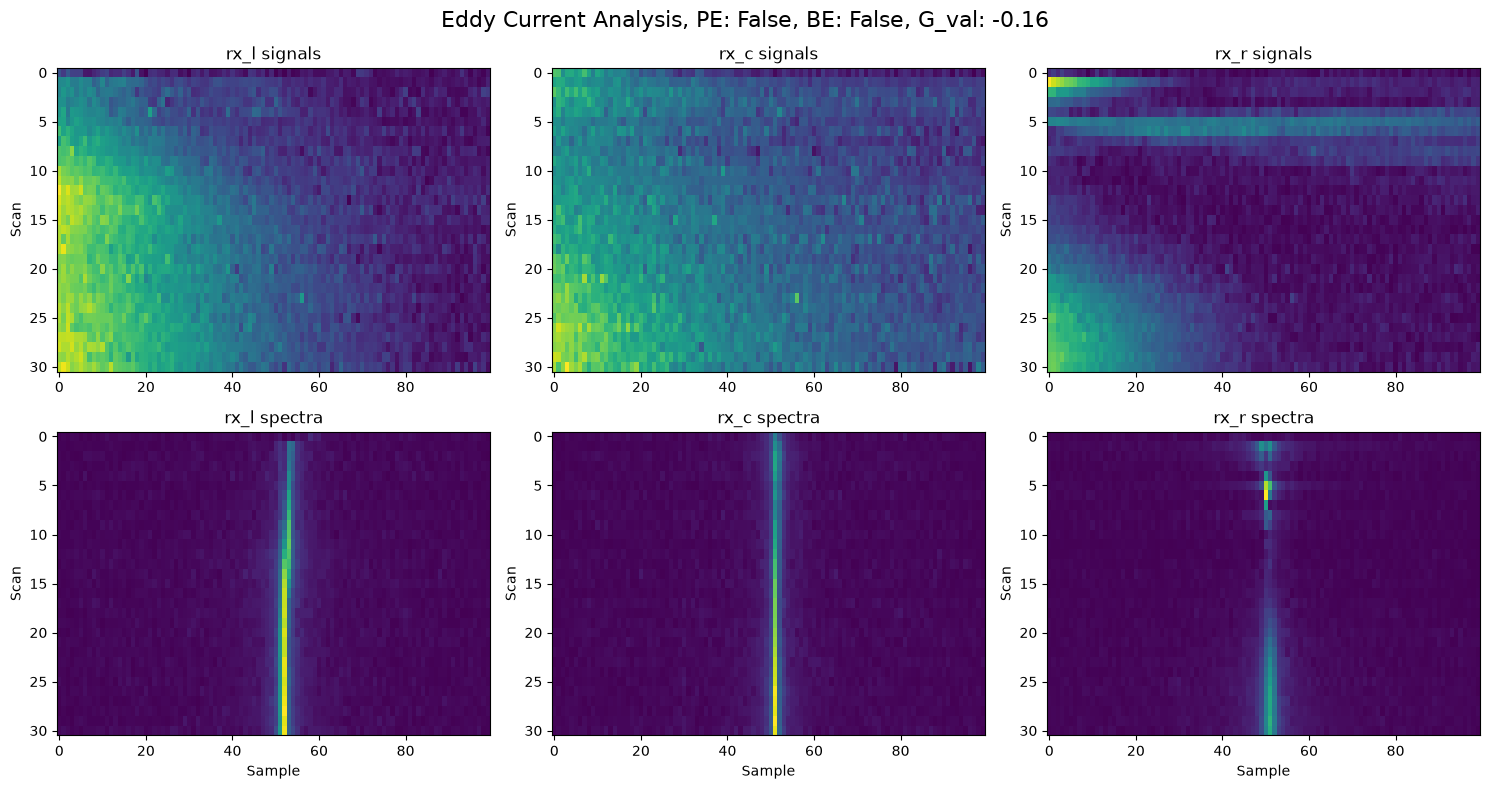

-132928.5357321339
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.08,  0.  ,  0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


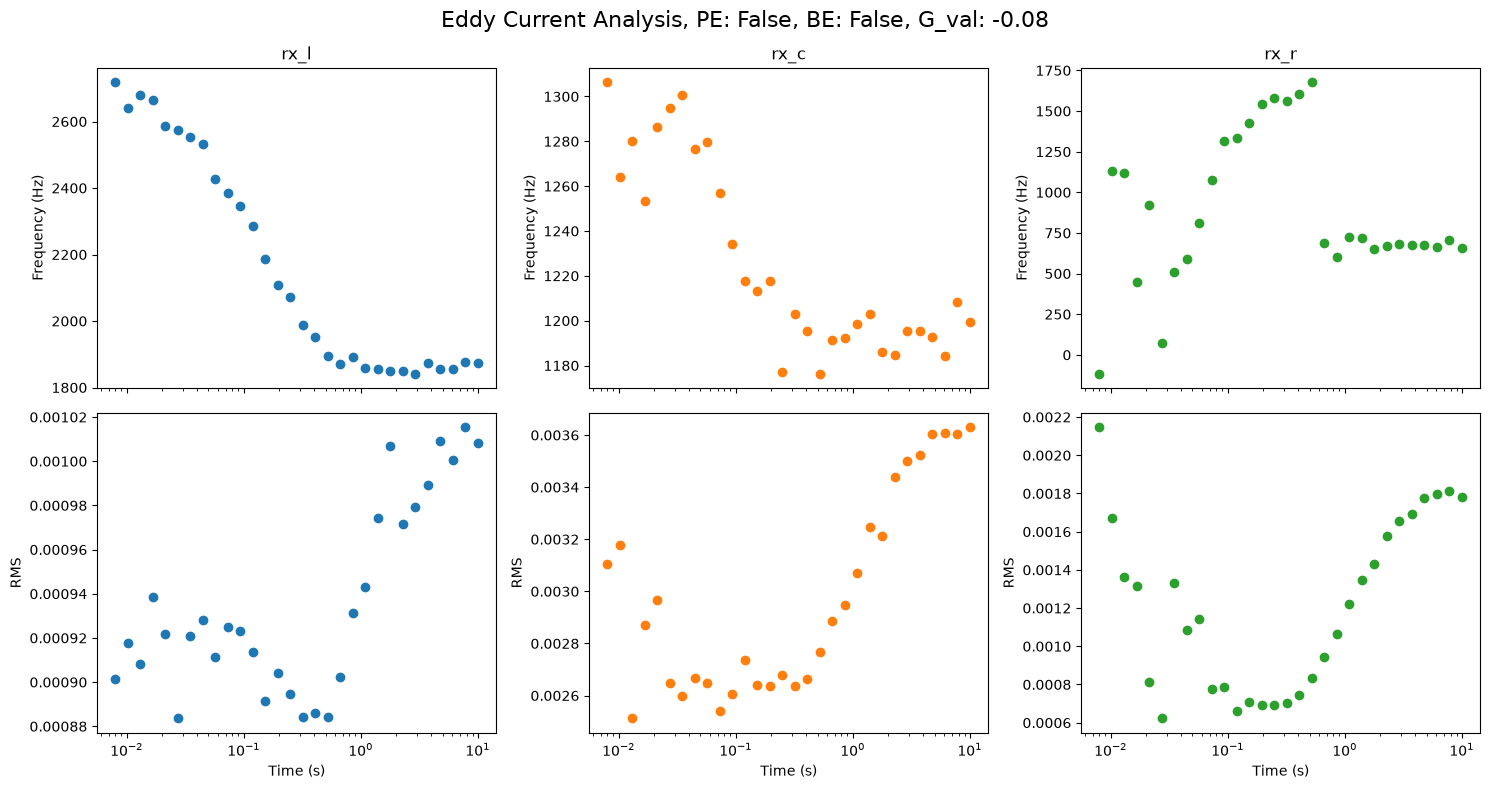

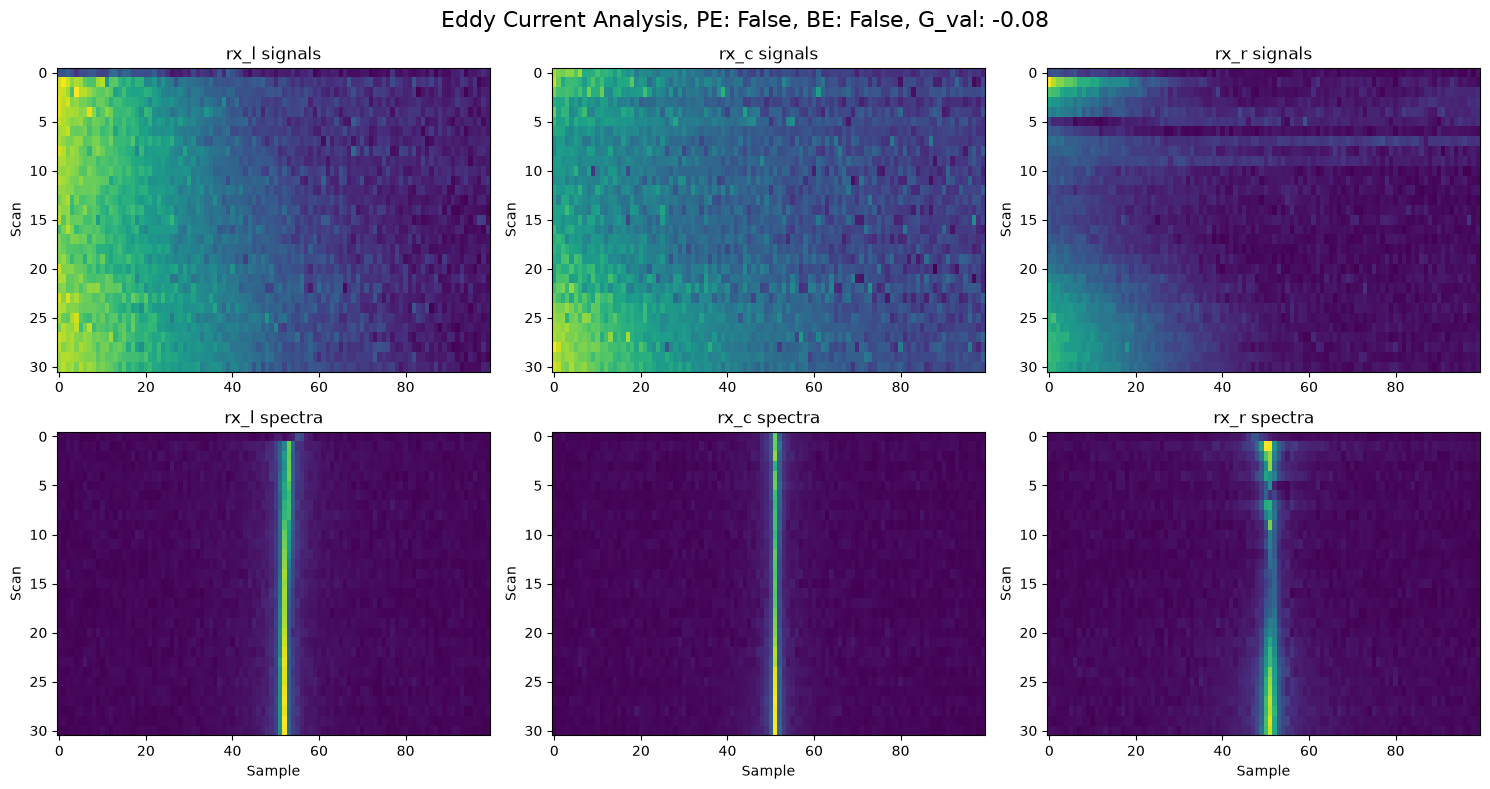

-79700.14992503745
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0., 0., 0.]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


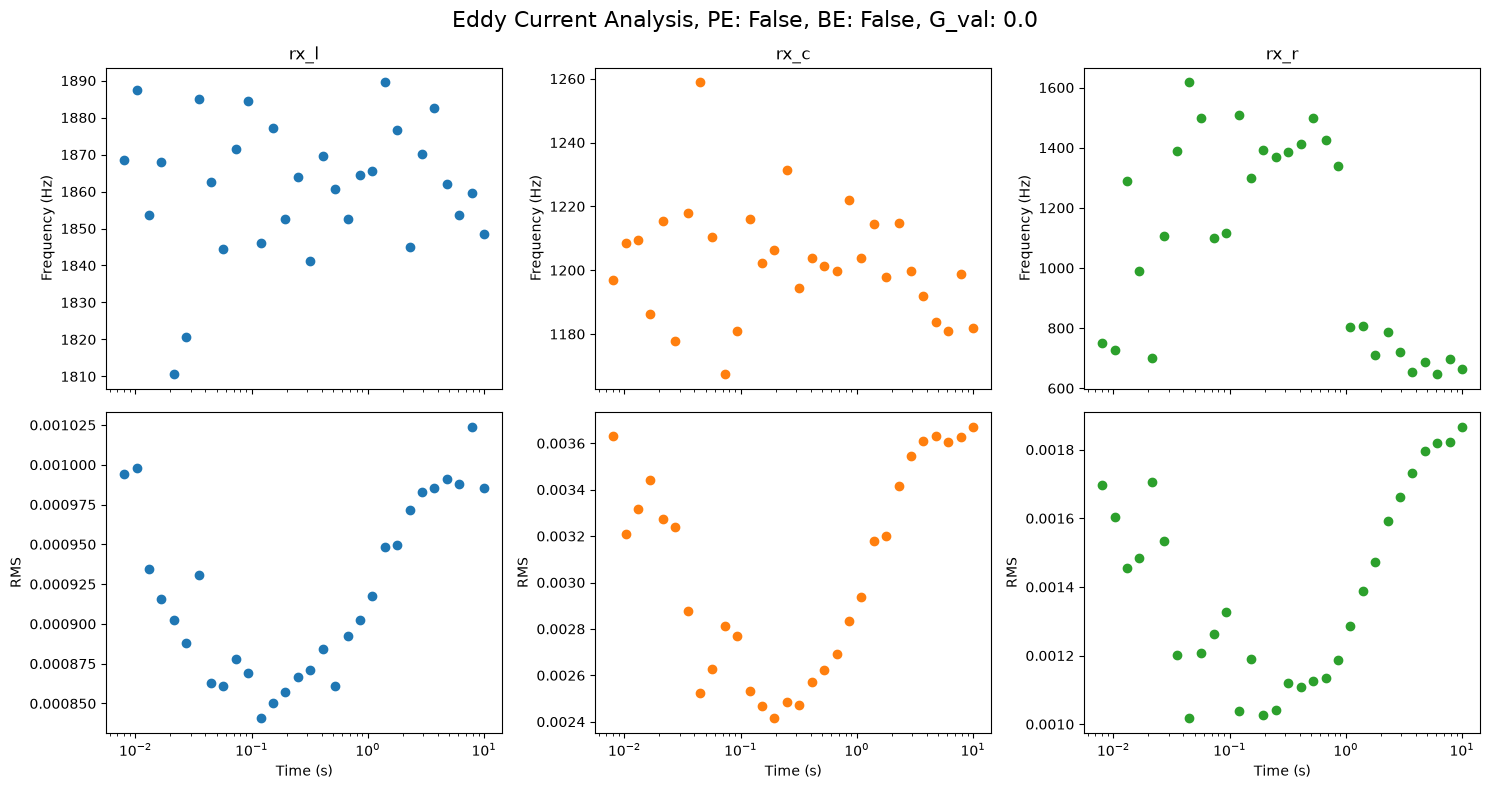

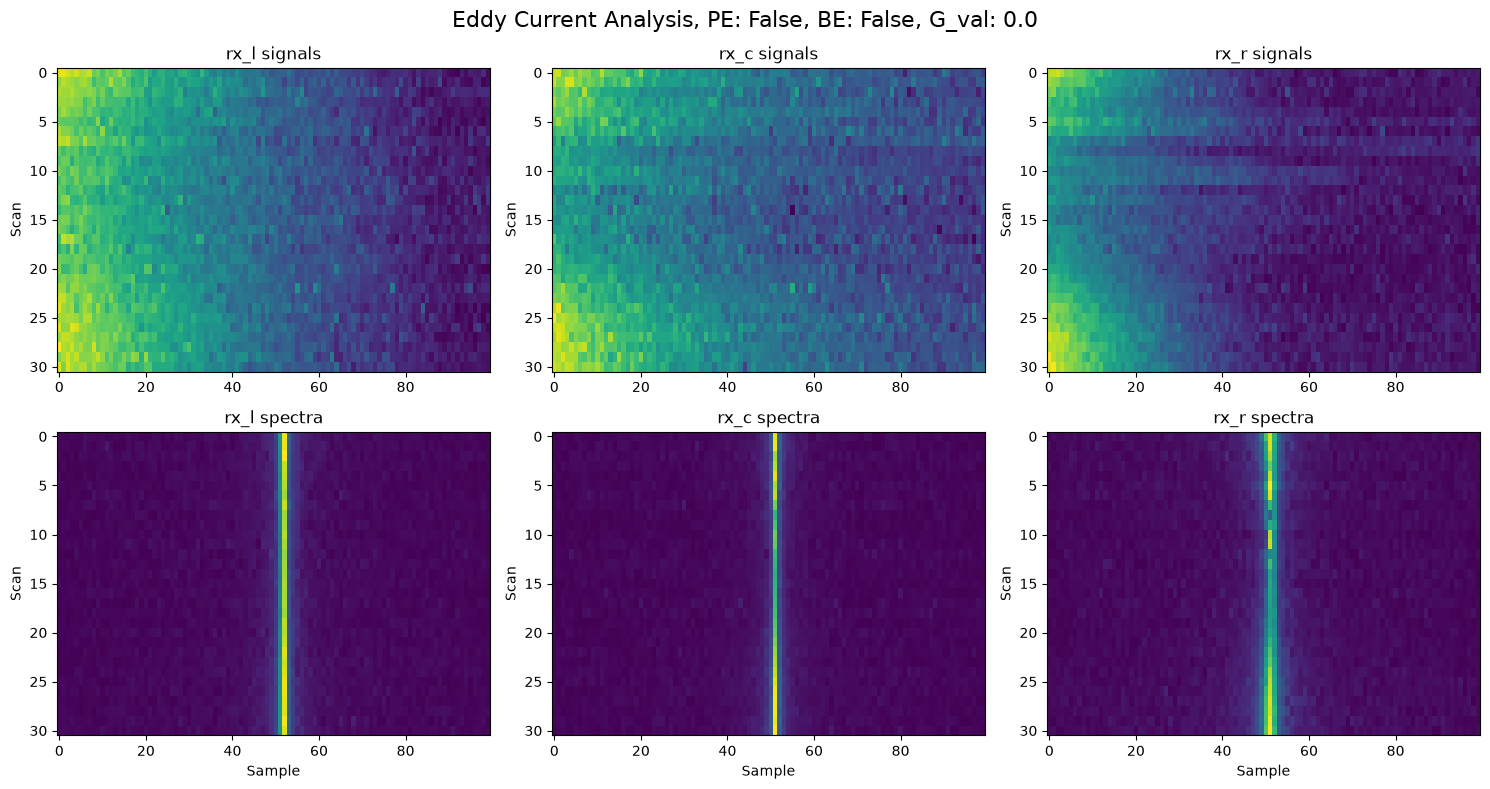

-12403.79810094952
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.08, 0.  , 0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


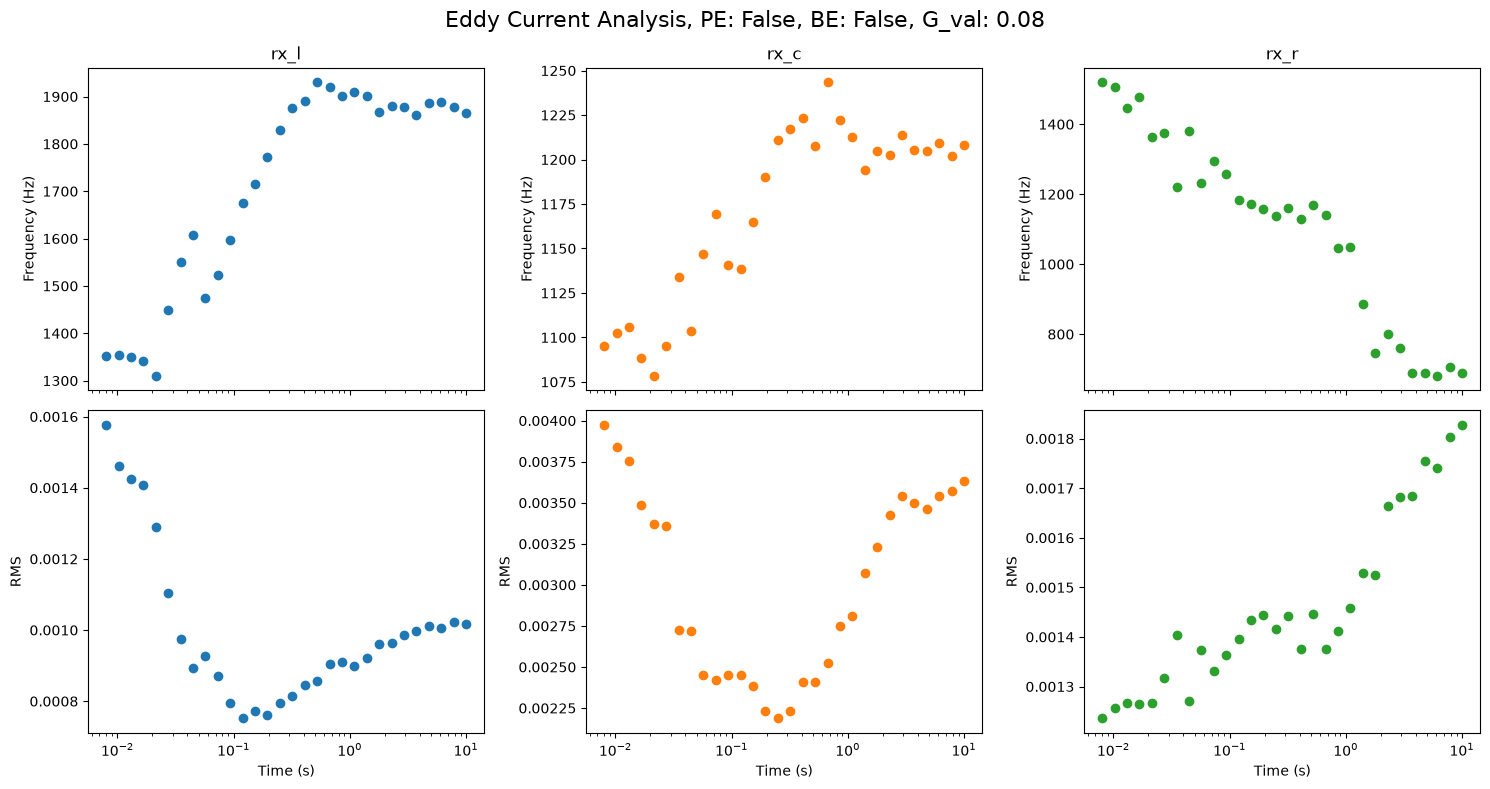

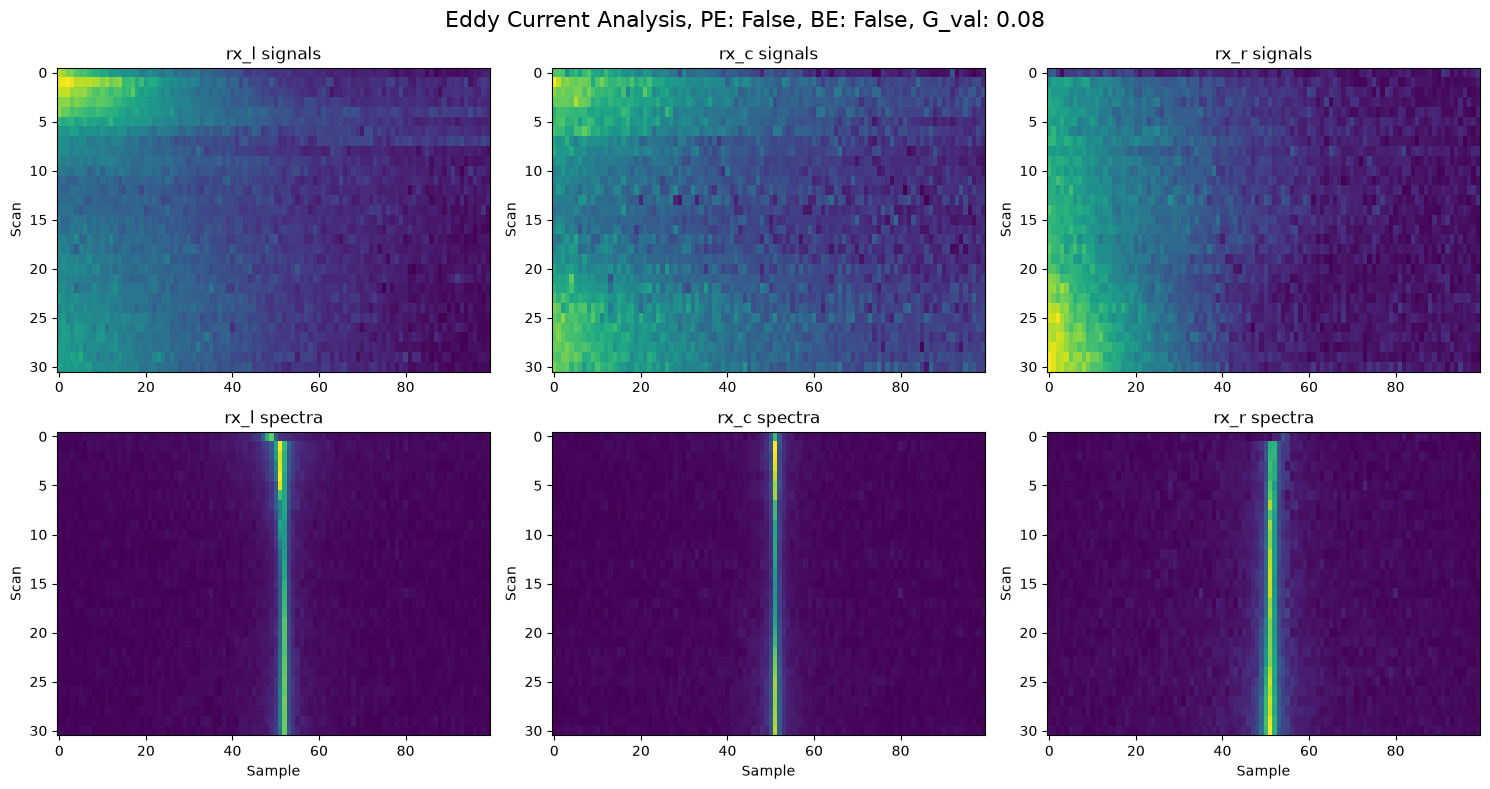

56941.529235382295
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.16, 0.  , 0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


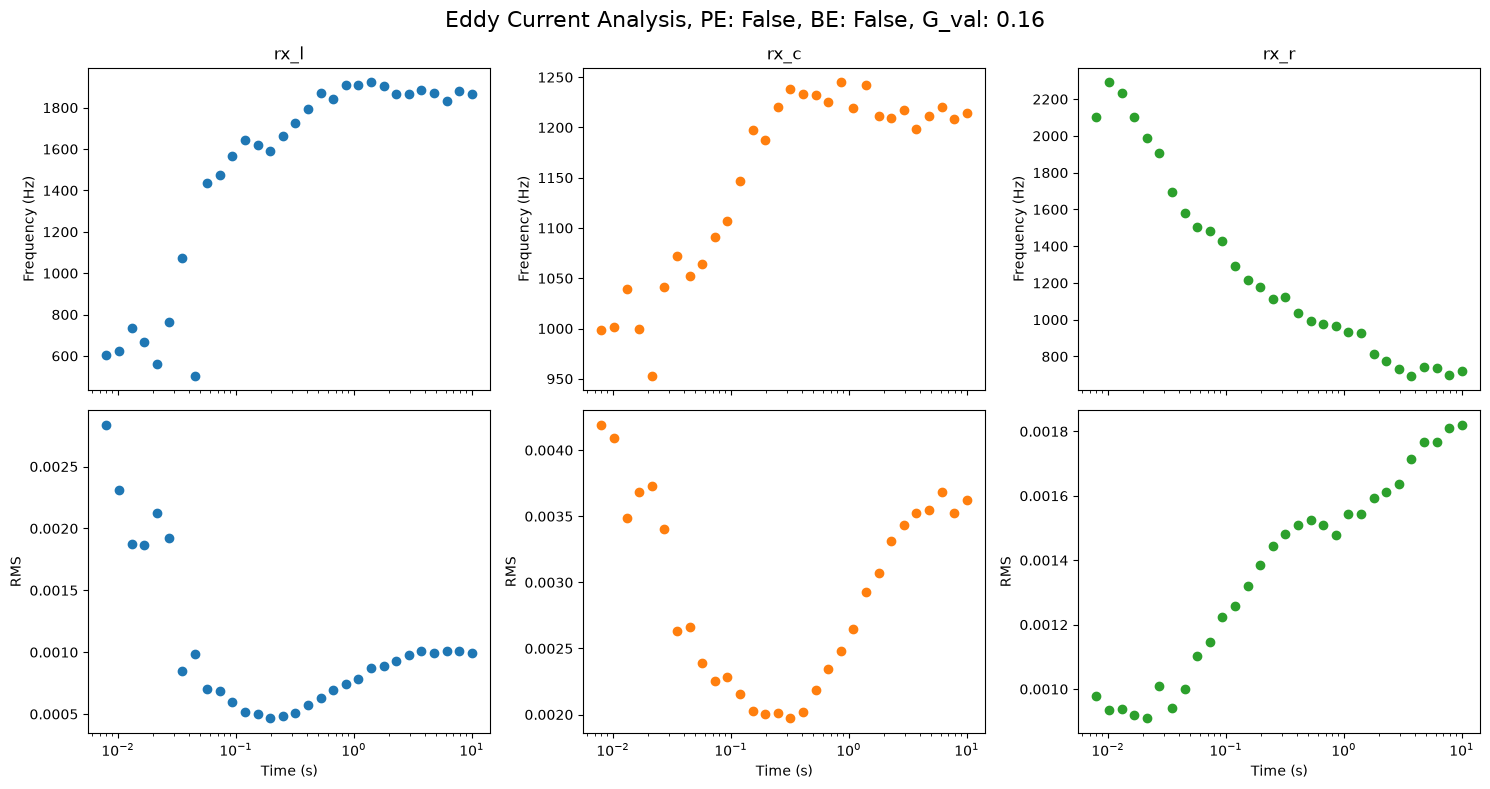

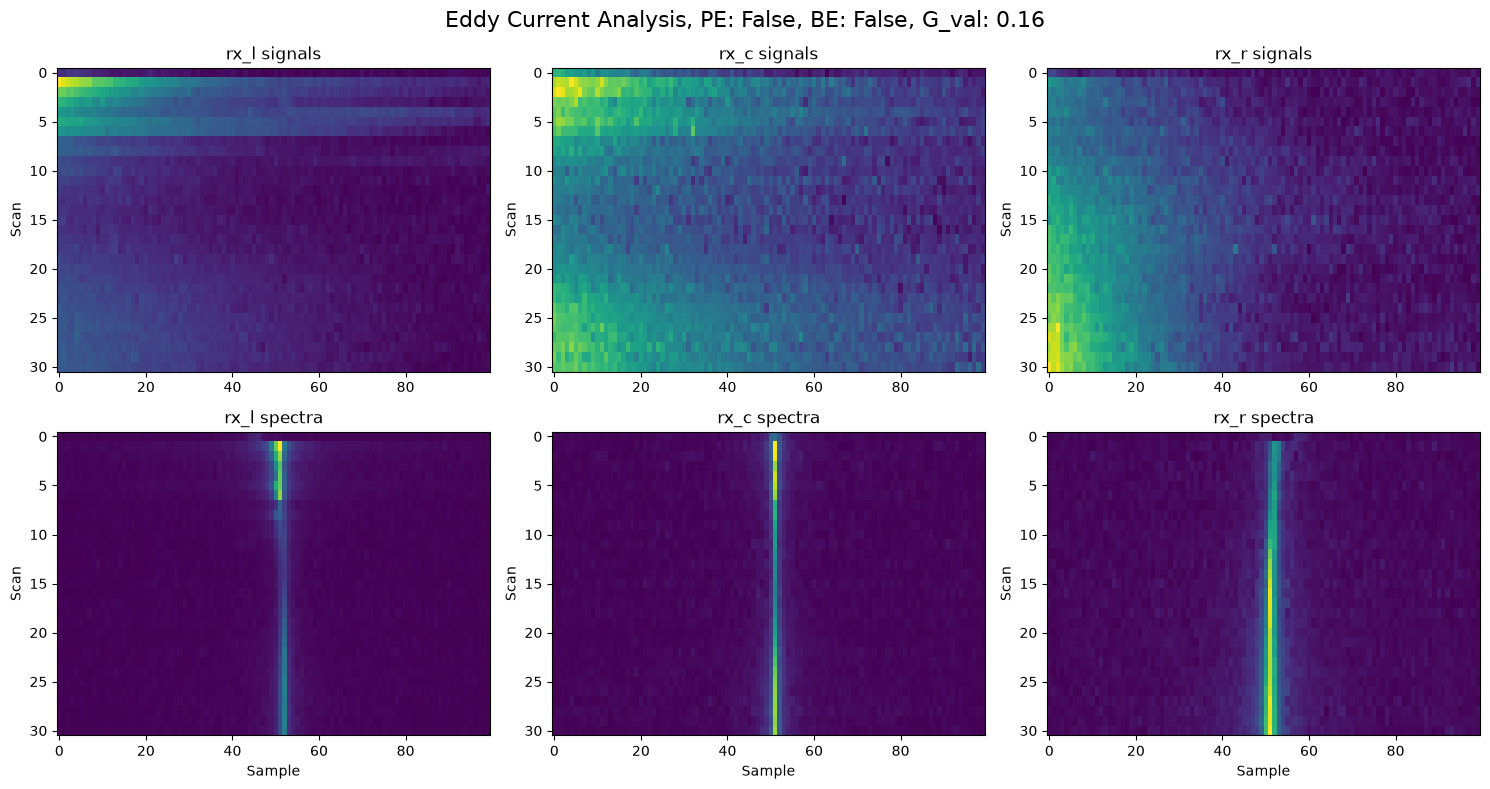

117426.28685657168
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.24, 0.  , 0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


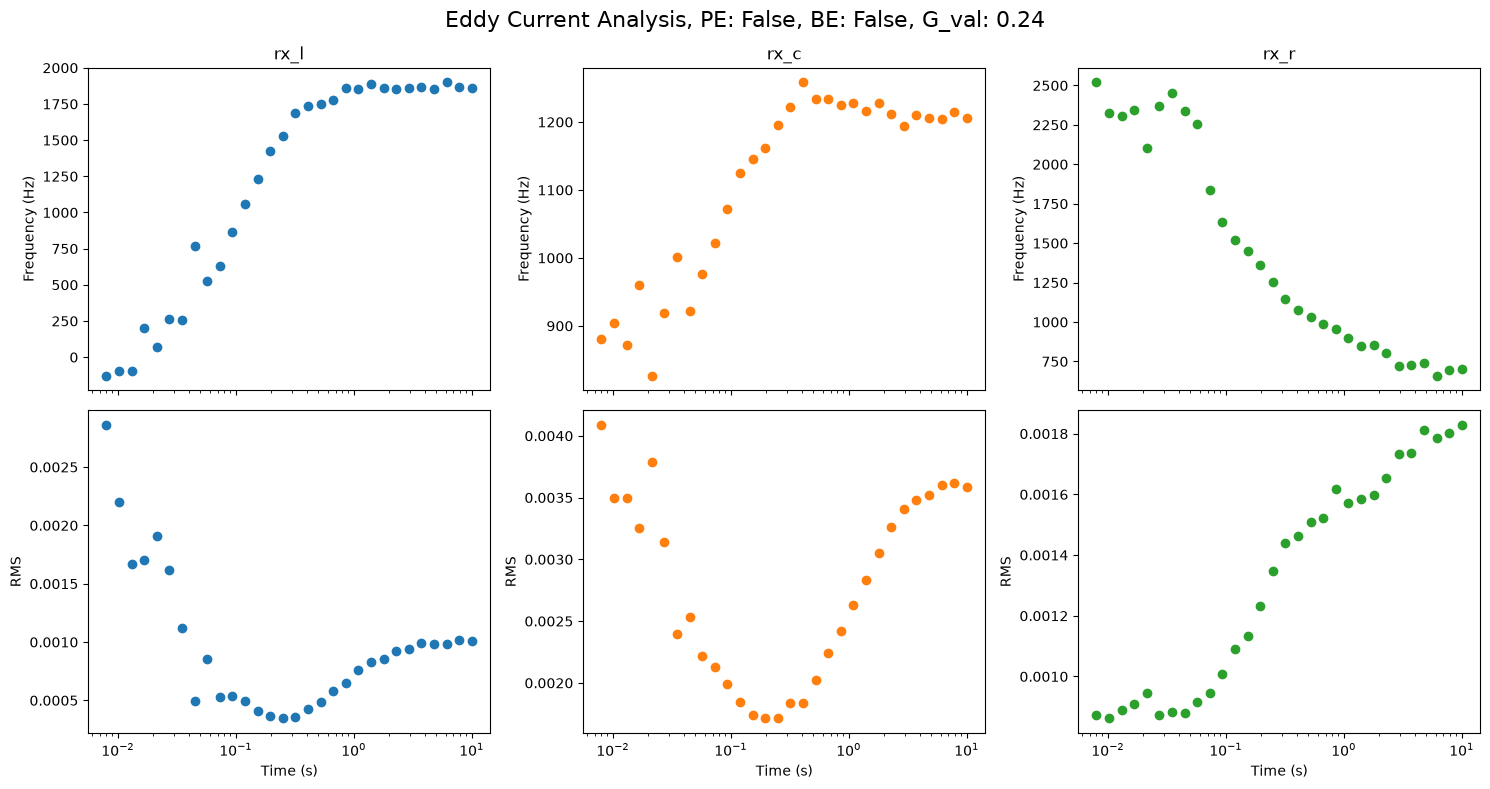

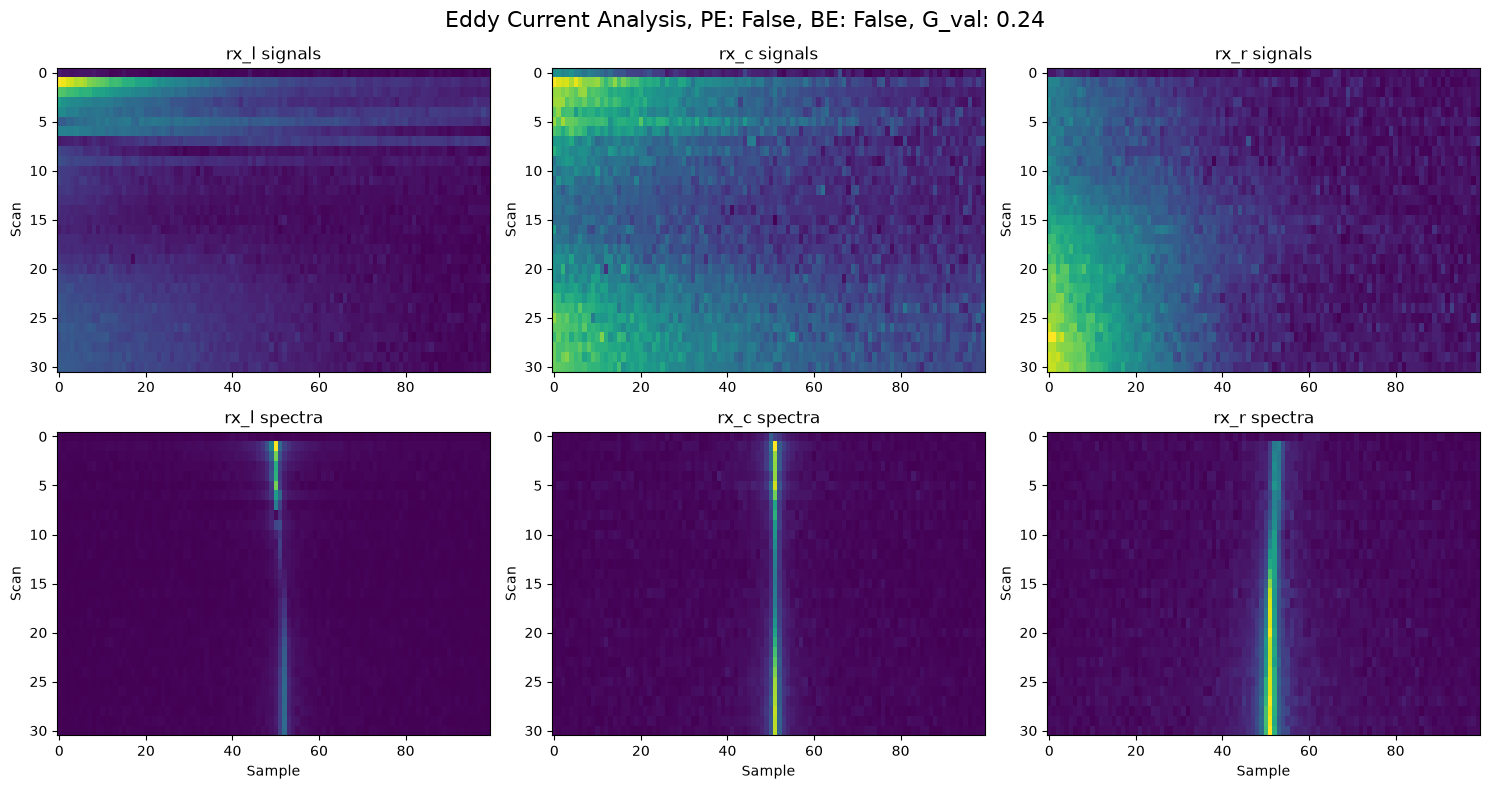

202918.54072963513
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.32, 0.  , 0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


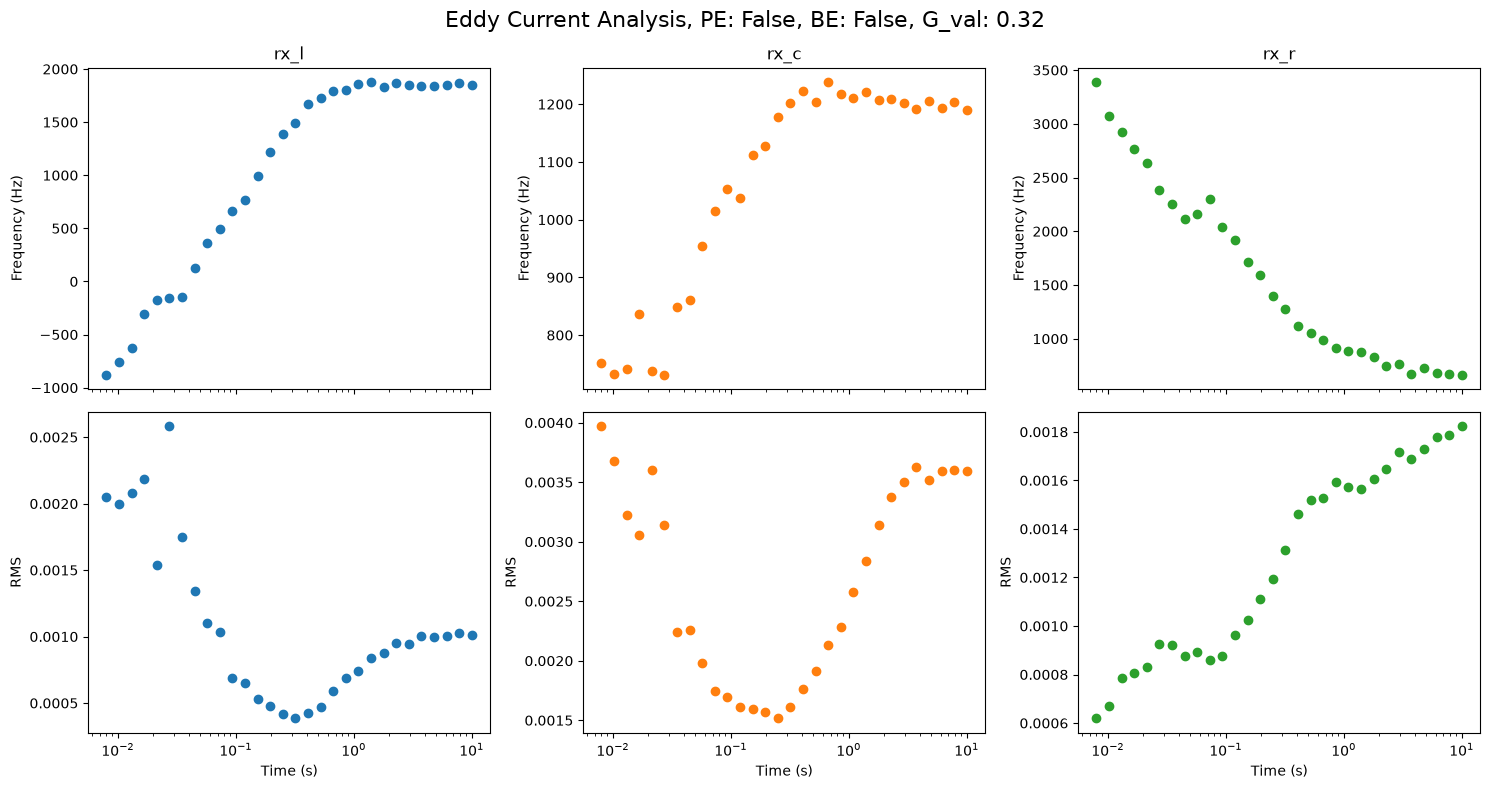

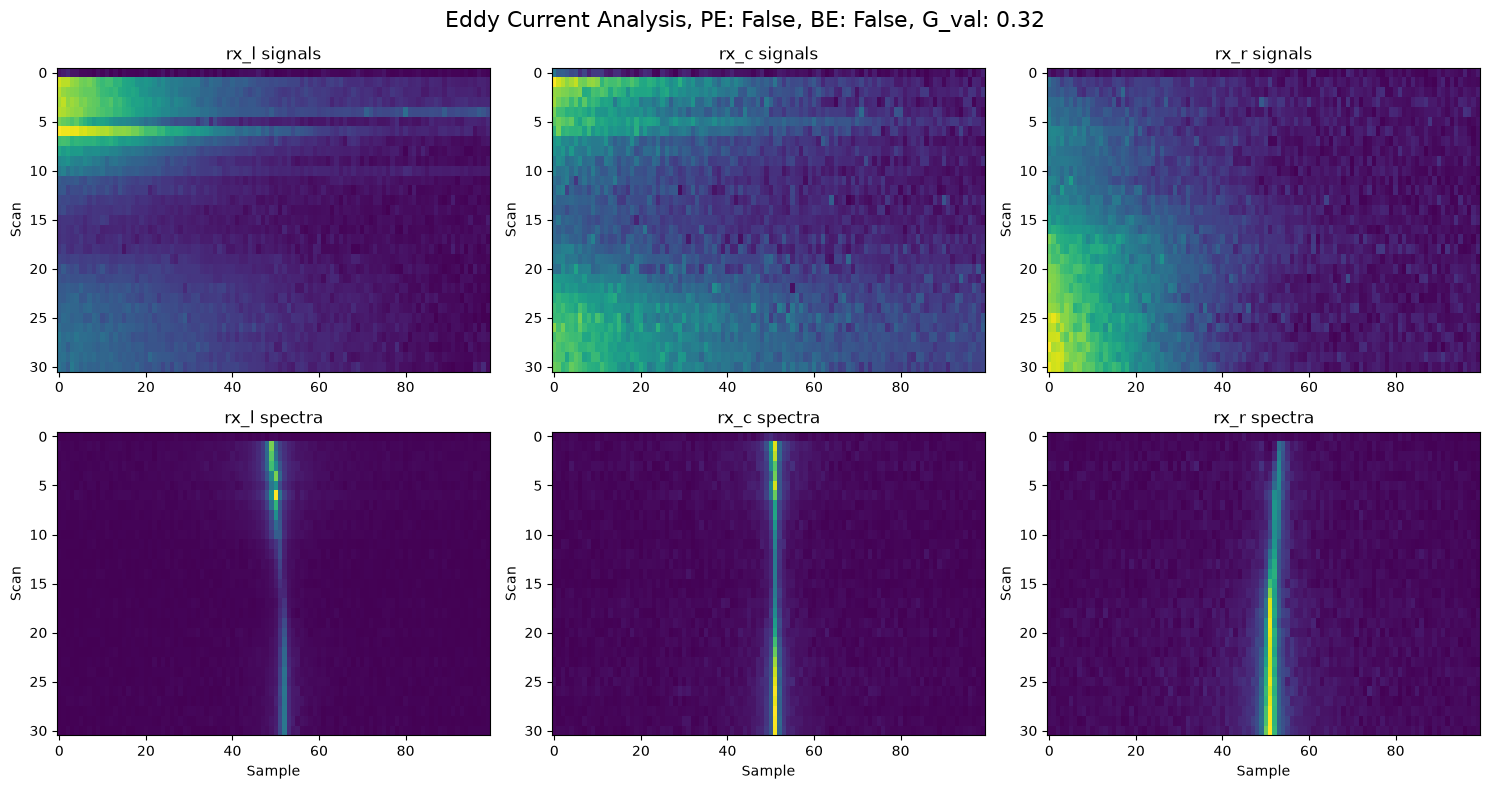

140444.77761119438
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.4, 0. , 0. ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis OFF
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


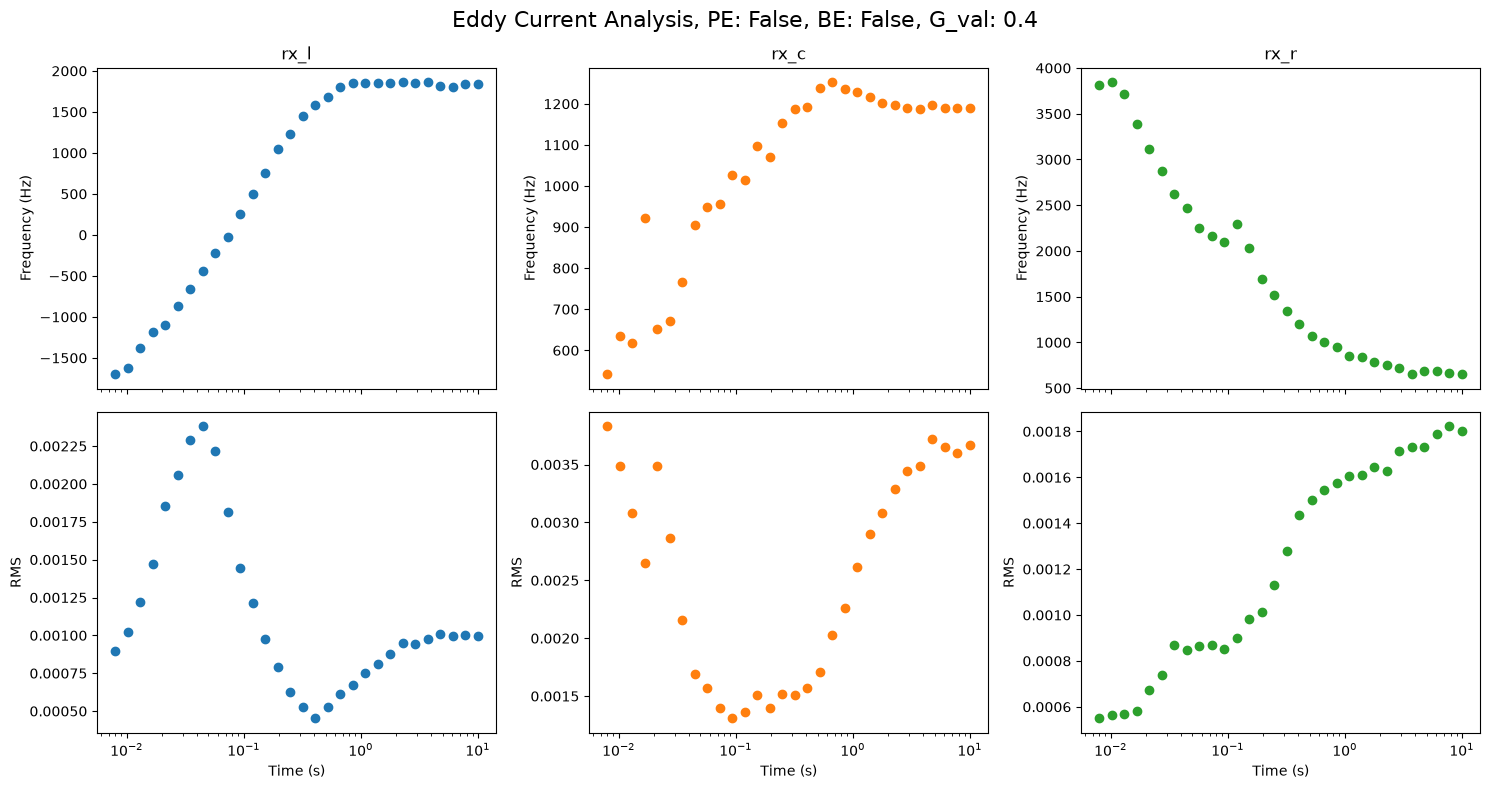

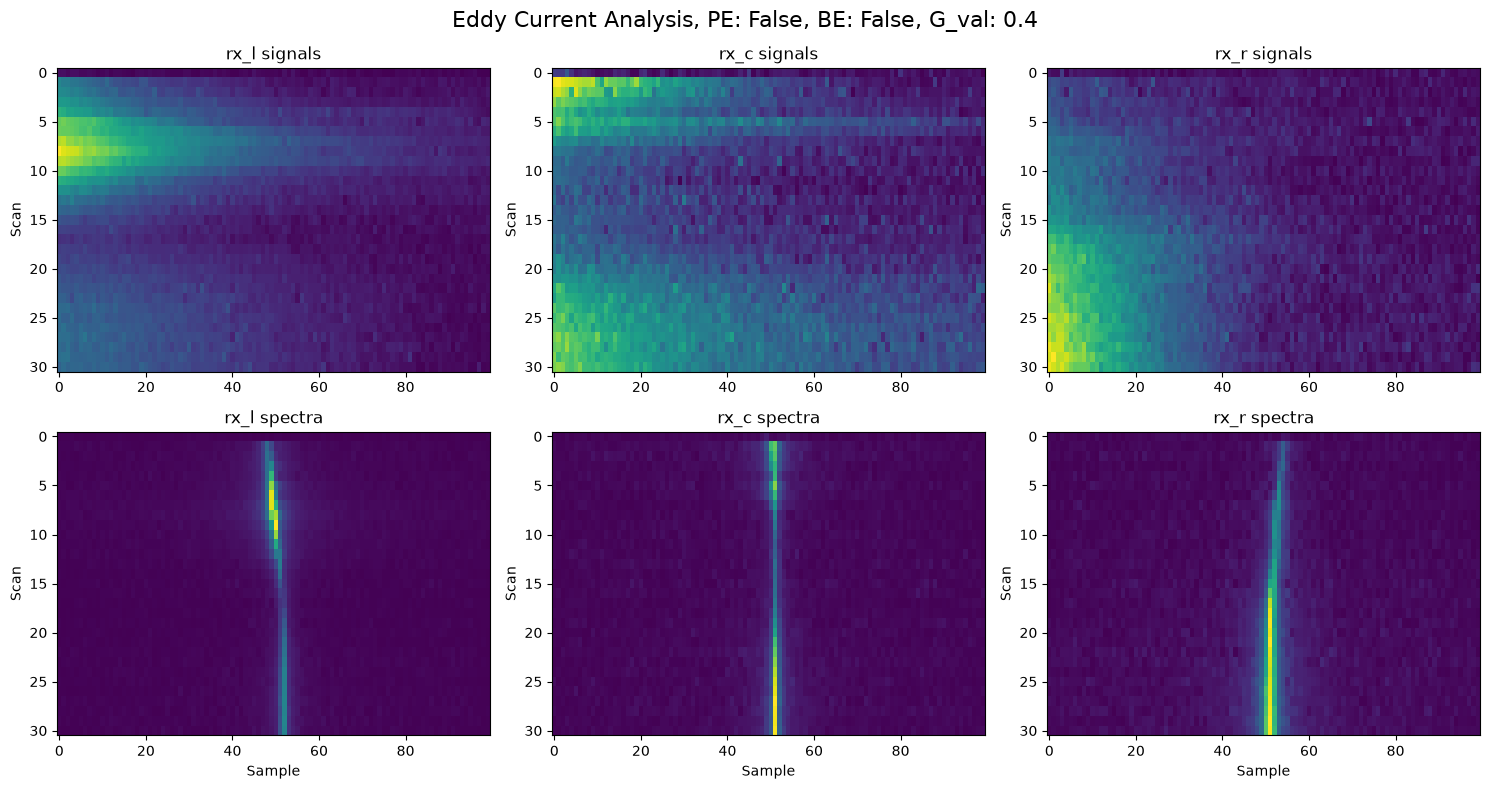

214202.89855072458
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.4,  0. ,  0. ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


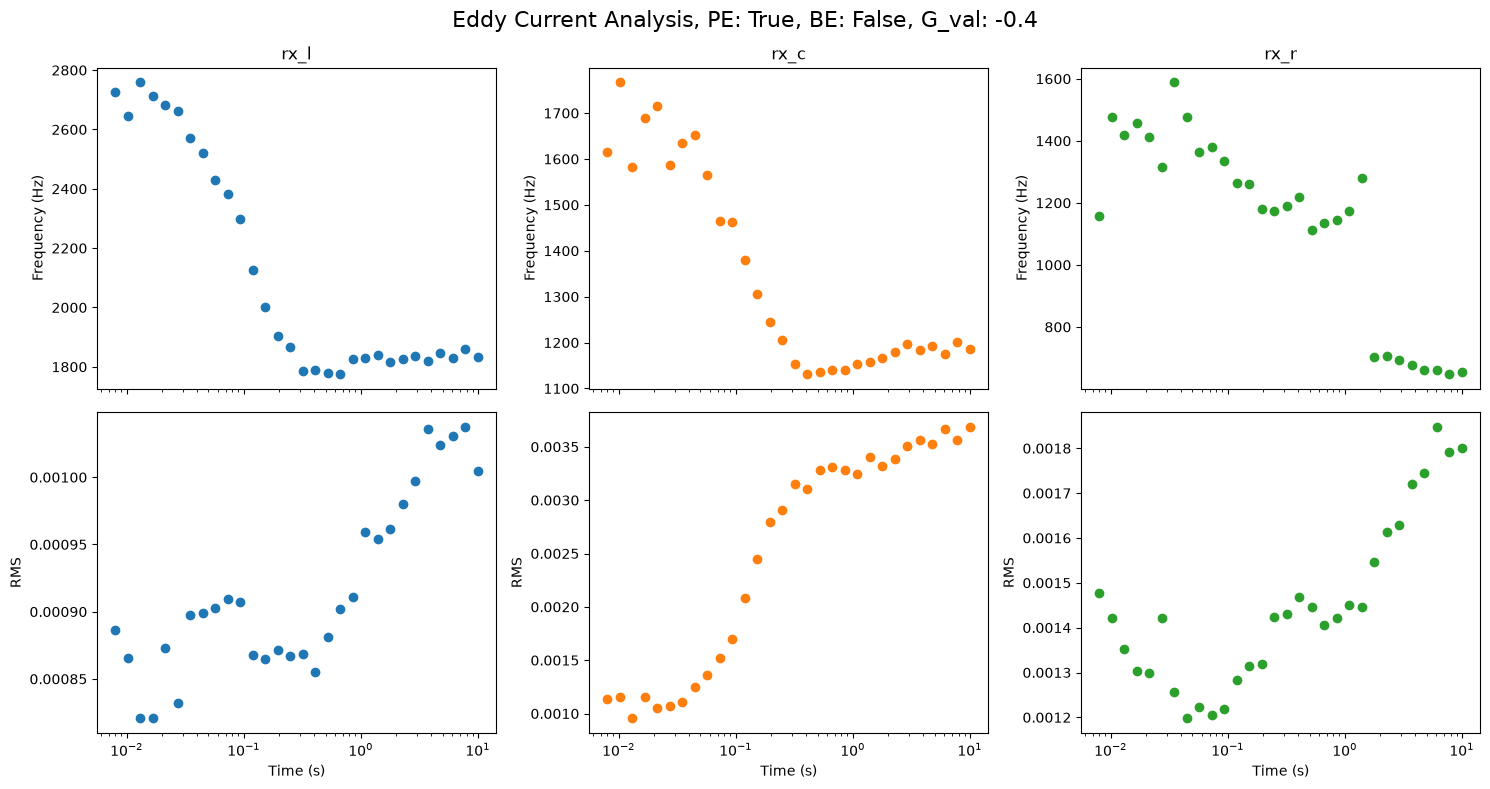

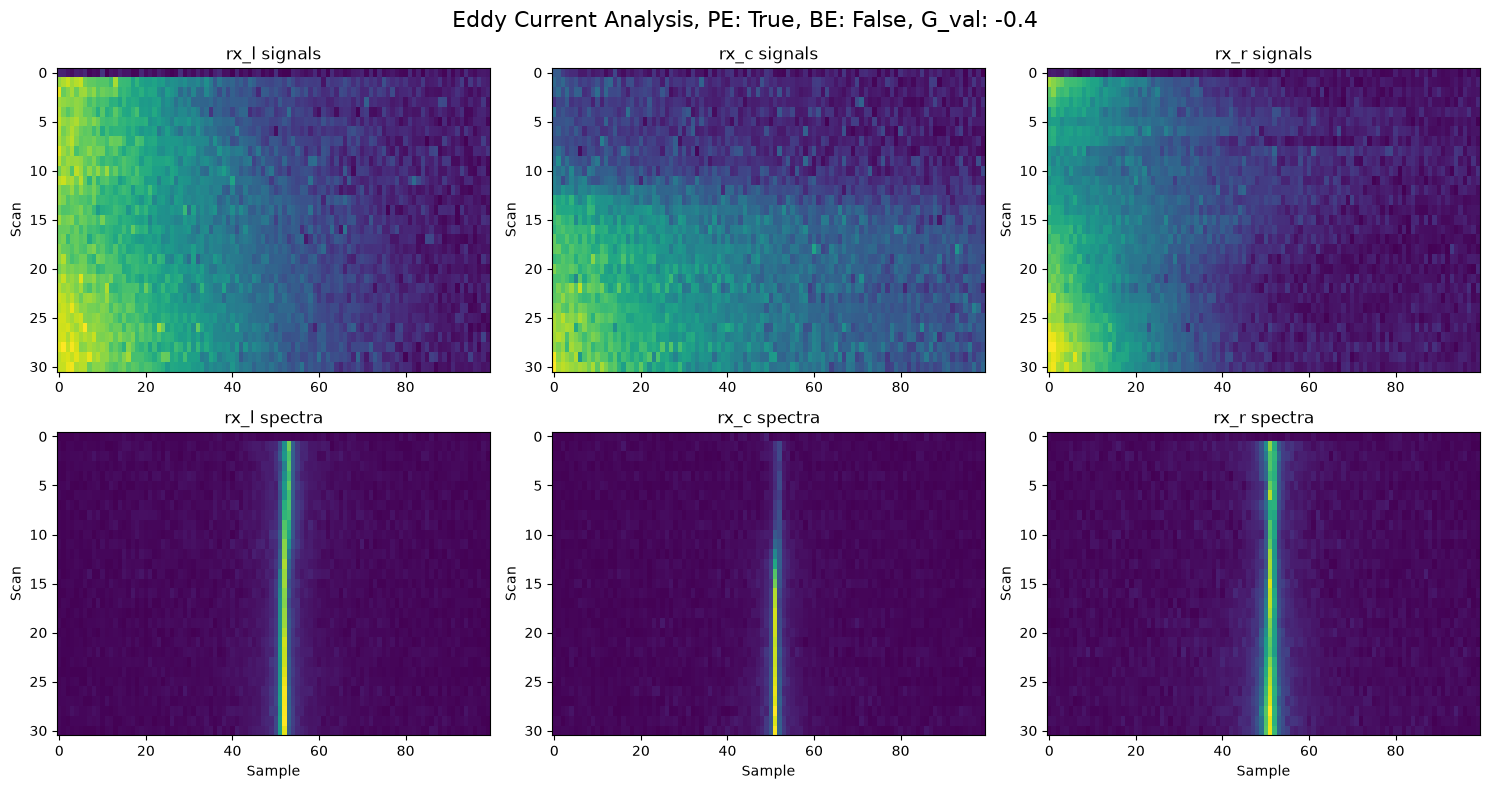

-267996.00199900044
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.32,  0.  ,  0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


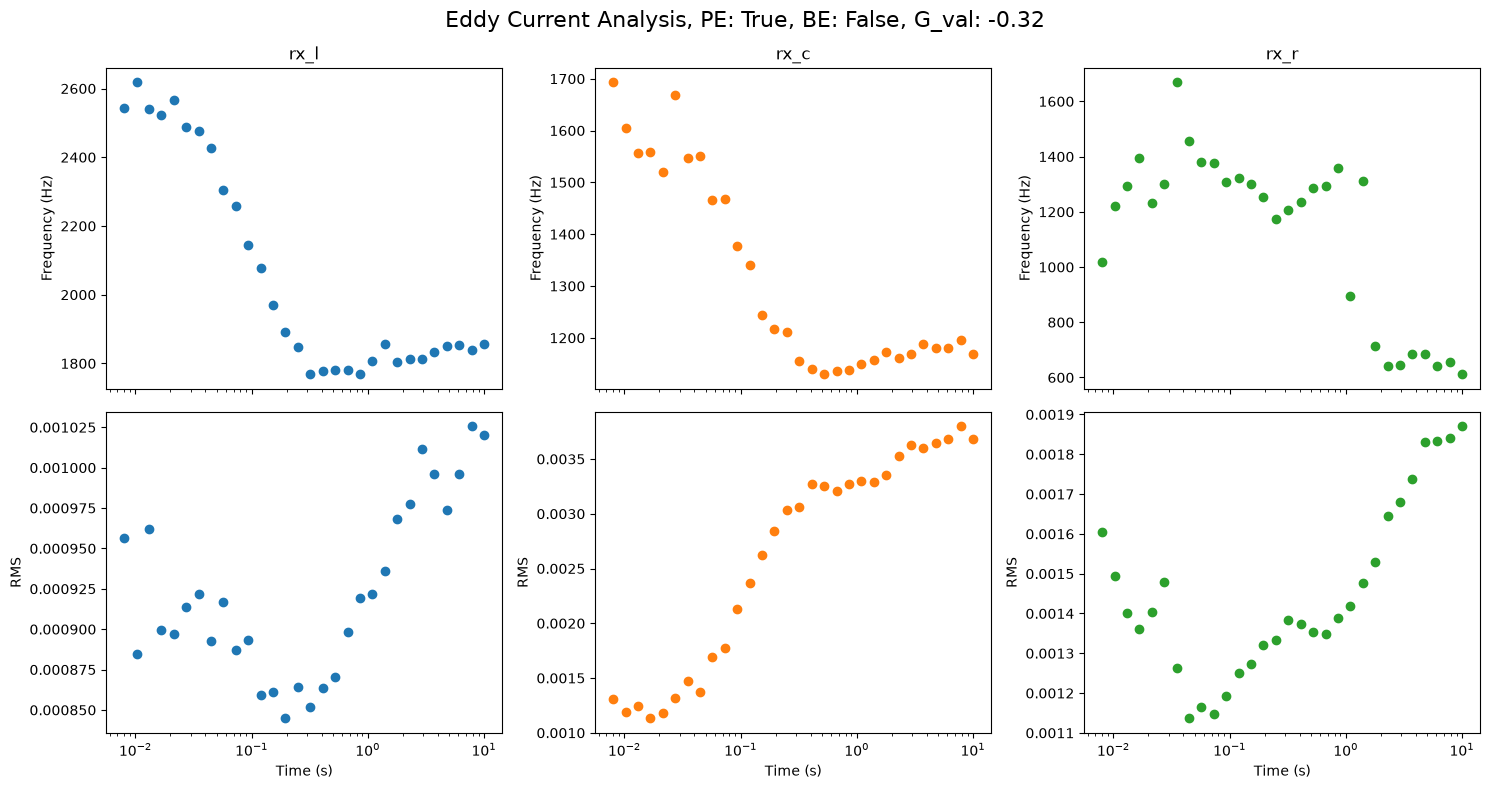

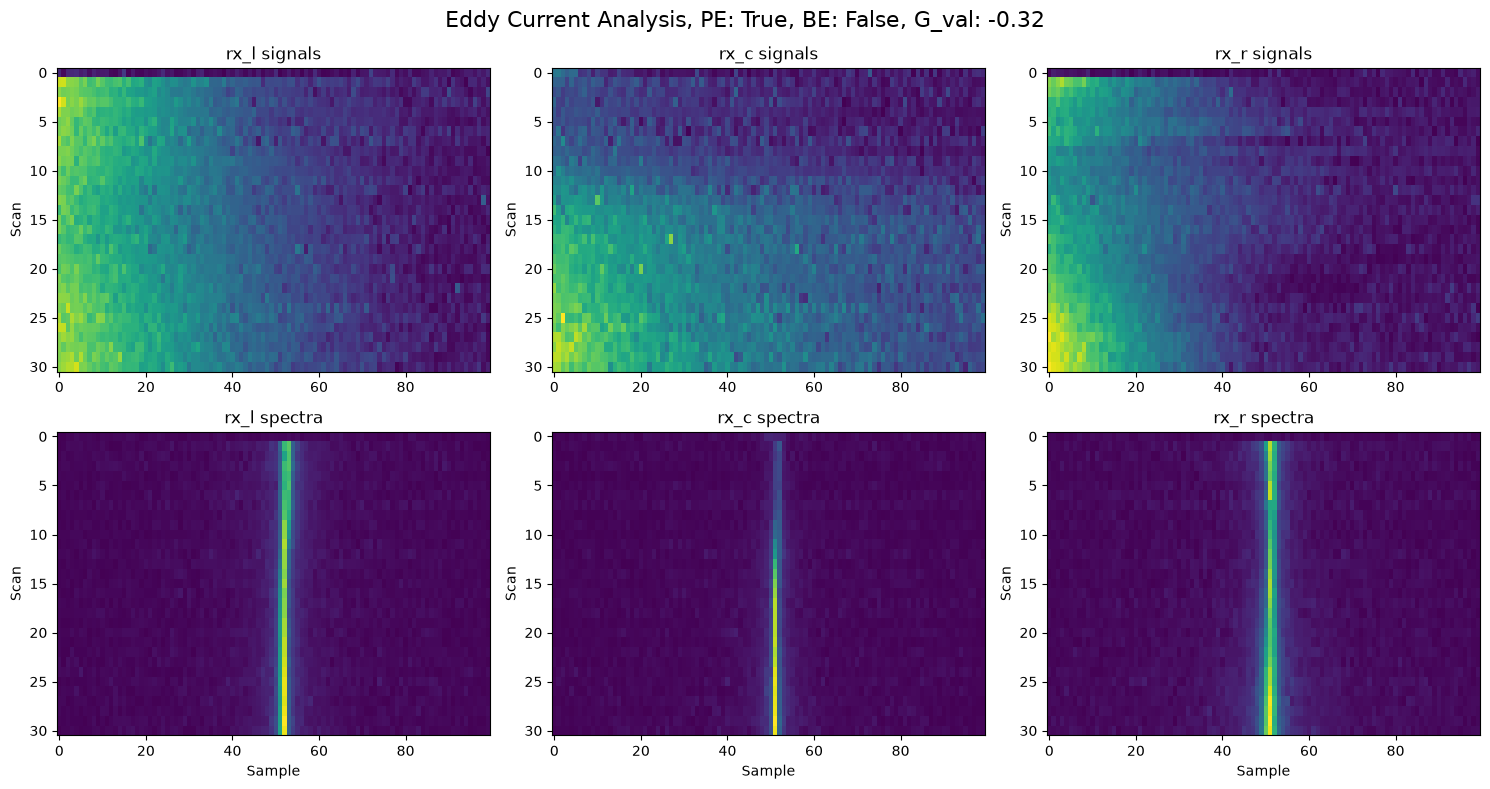

-154152.92353823085
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.24,  0.  ,  0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


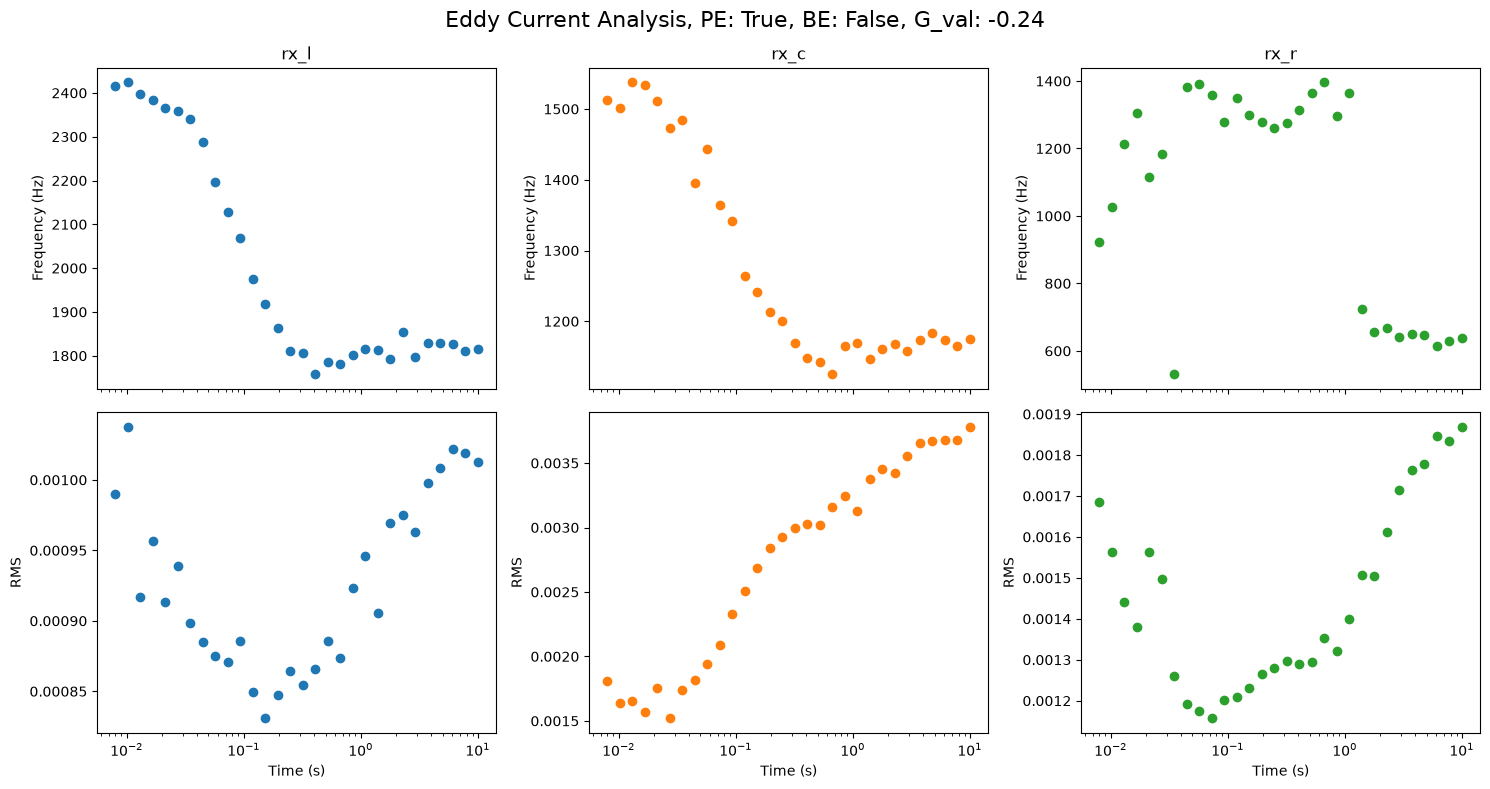

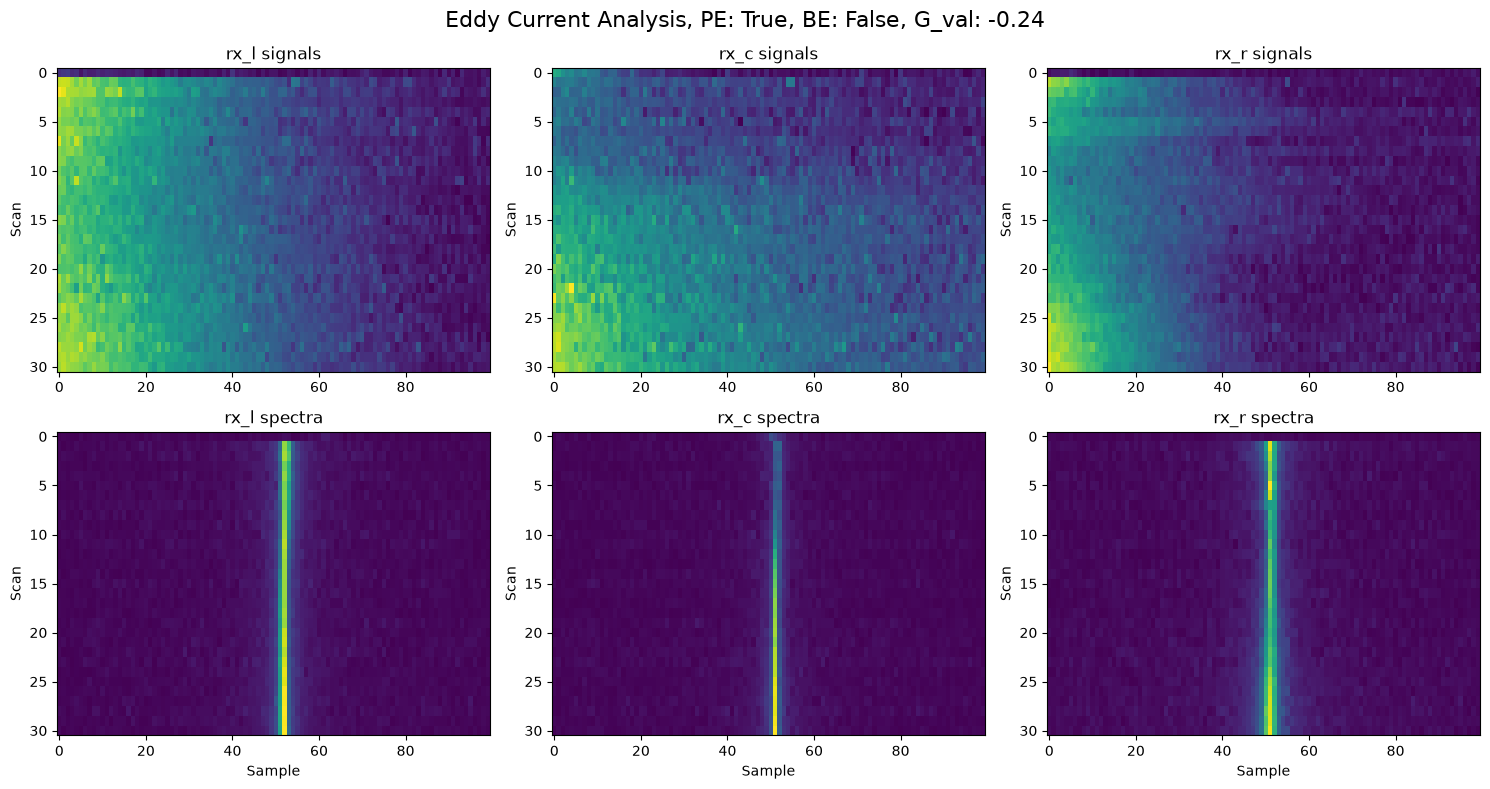

-154962.51874062966
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.16,  0.  ,  0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


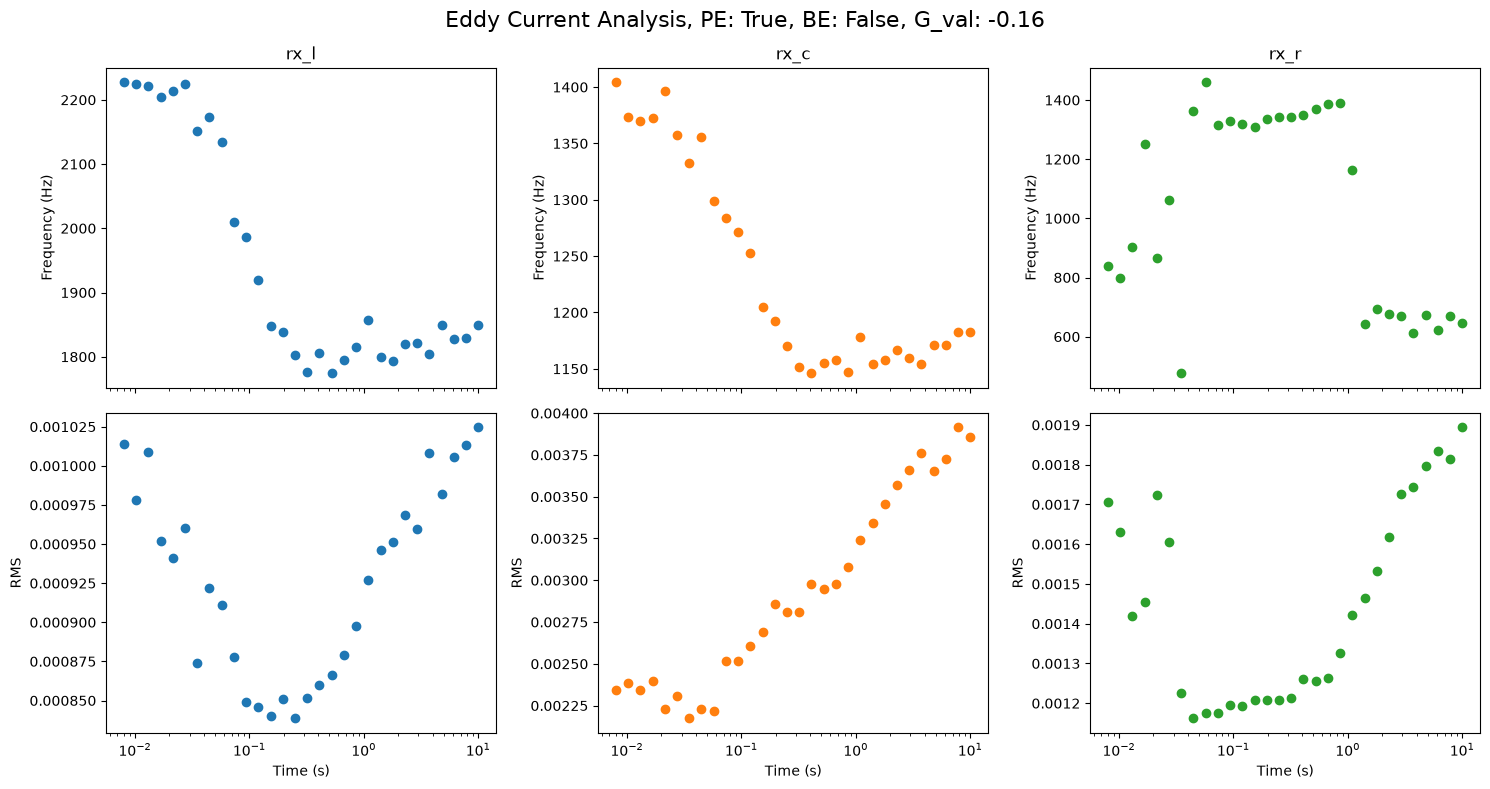

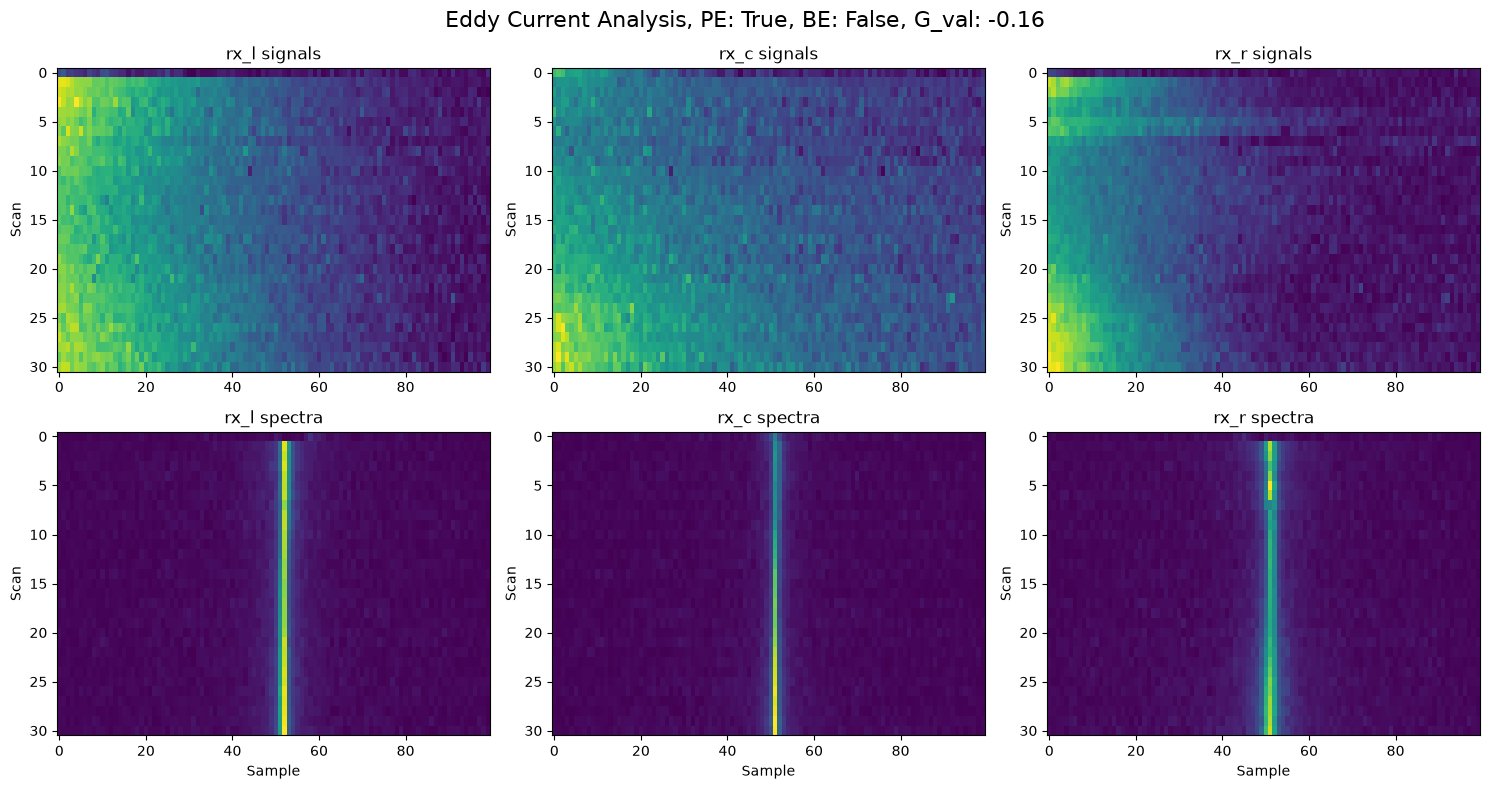

-133363.31834082954
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([-0.08,  0.  ,  0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


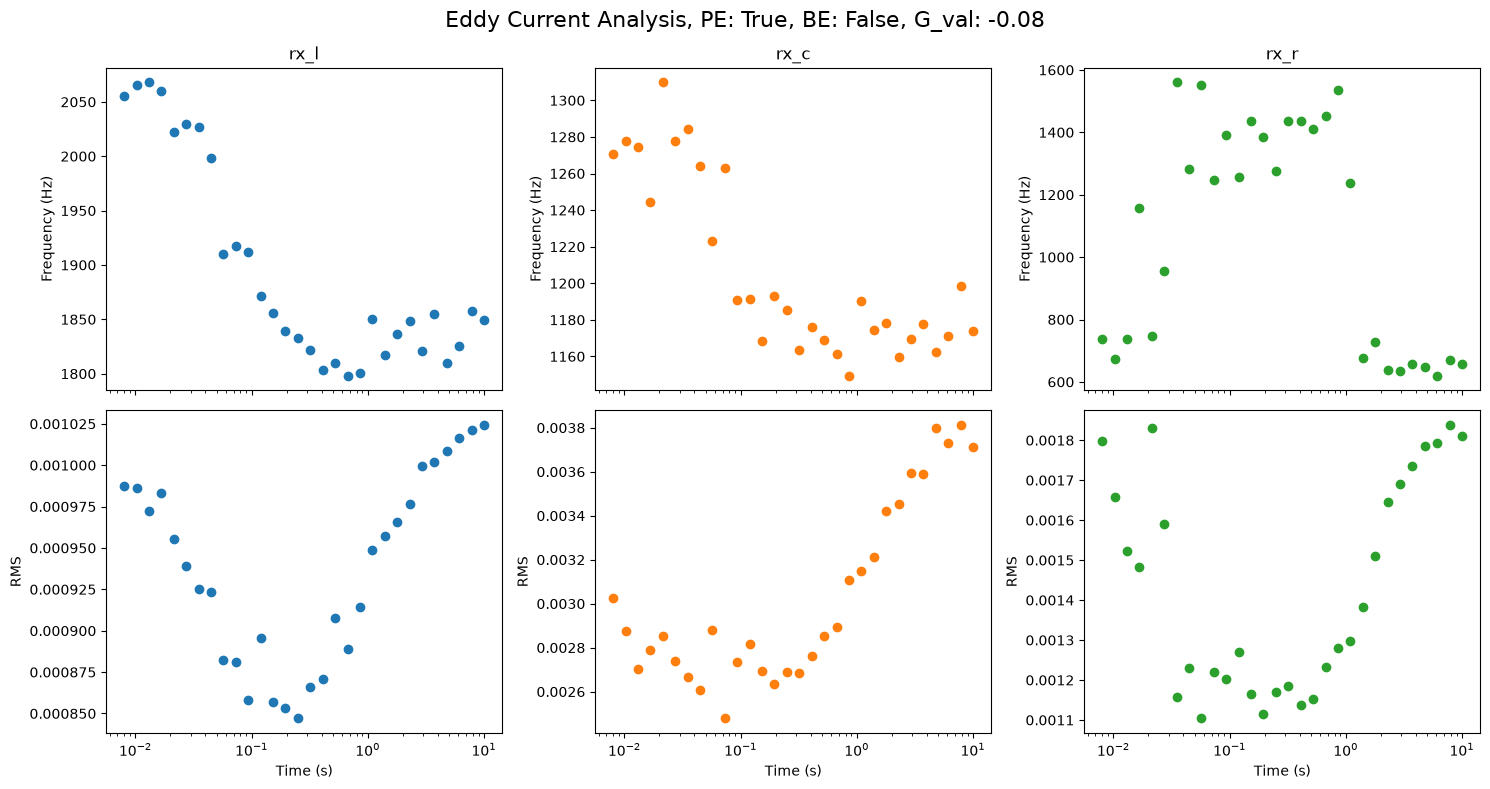

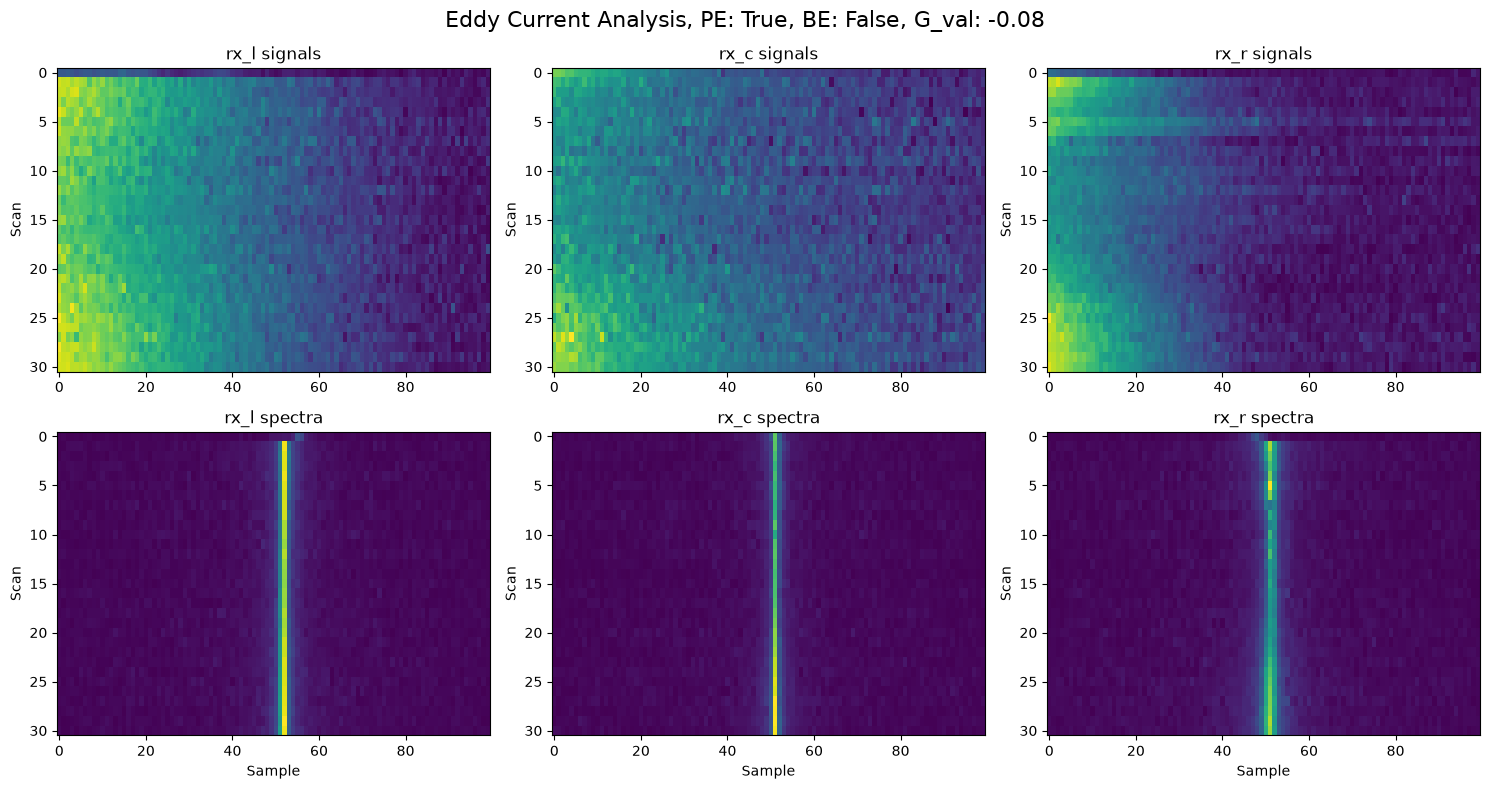

-71604.19790104945
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0., 0., 0.]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


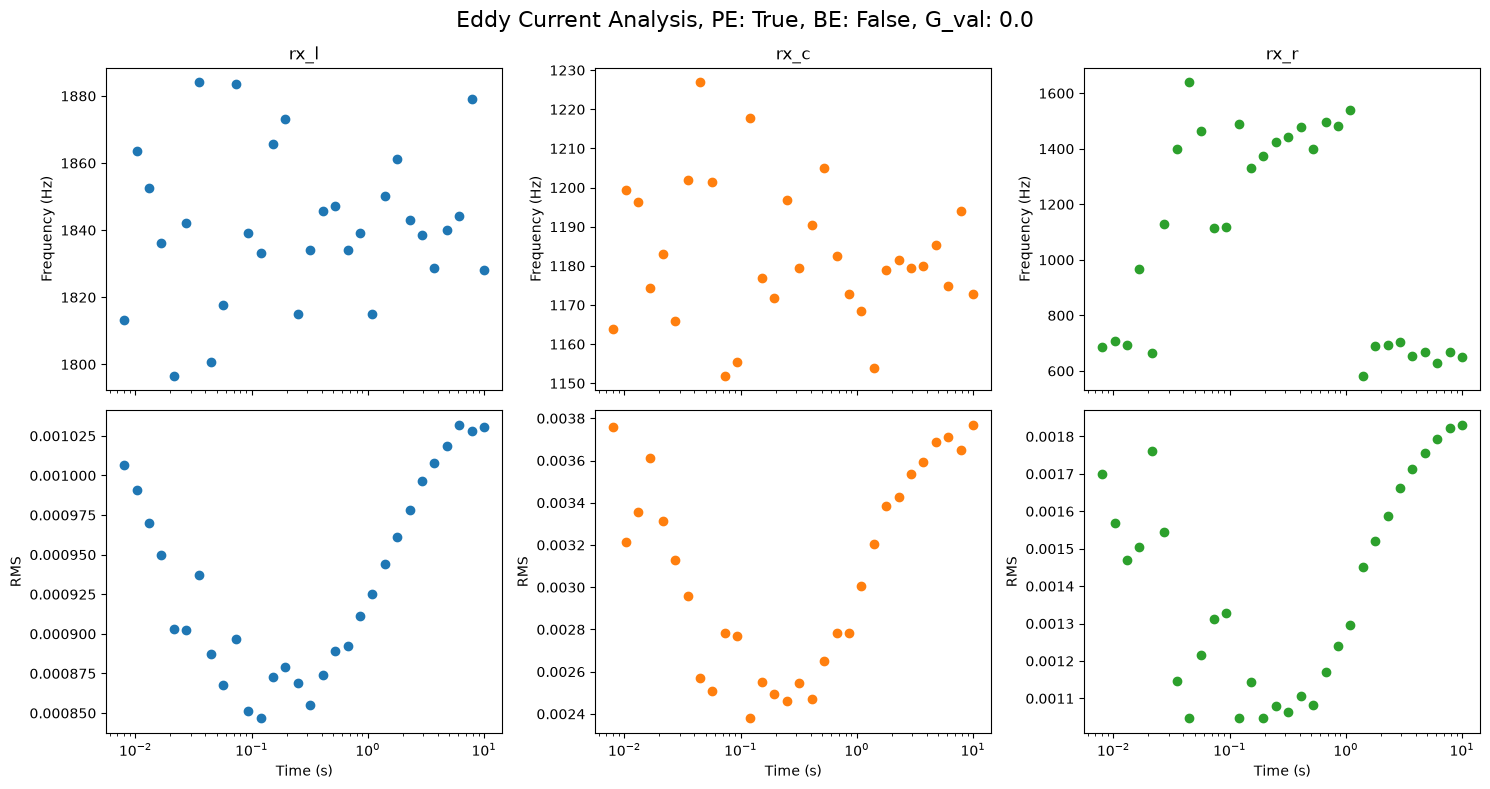

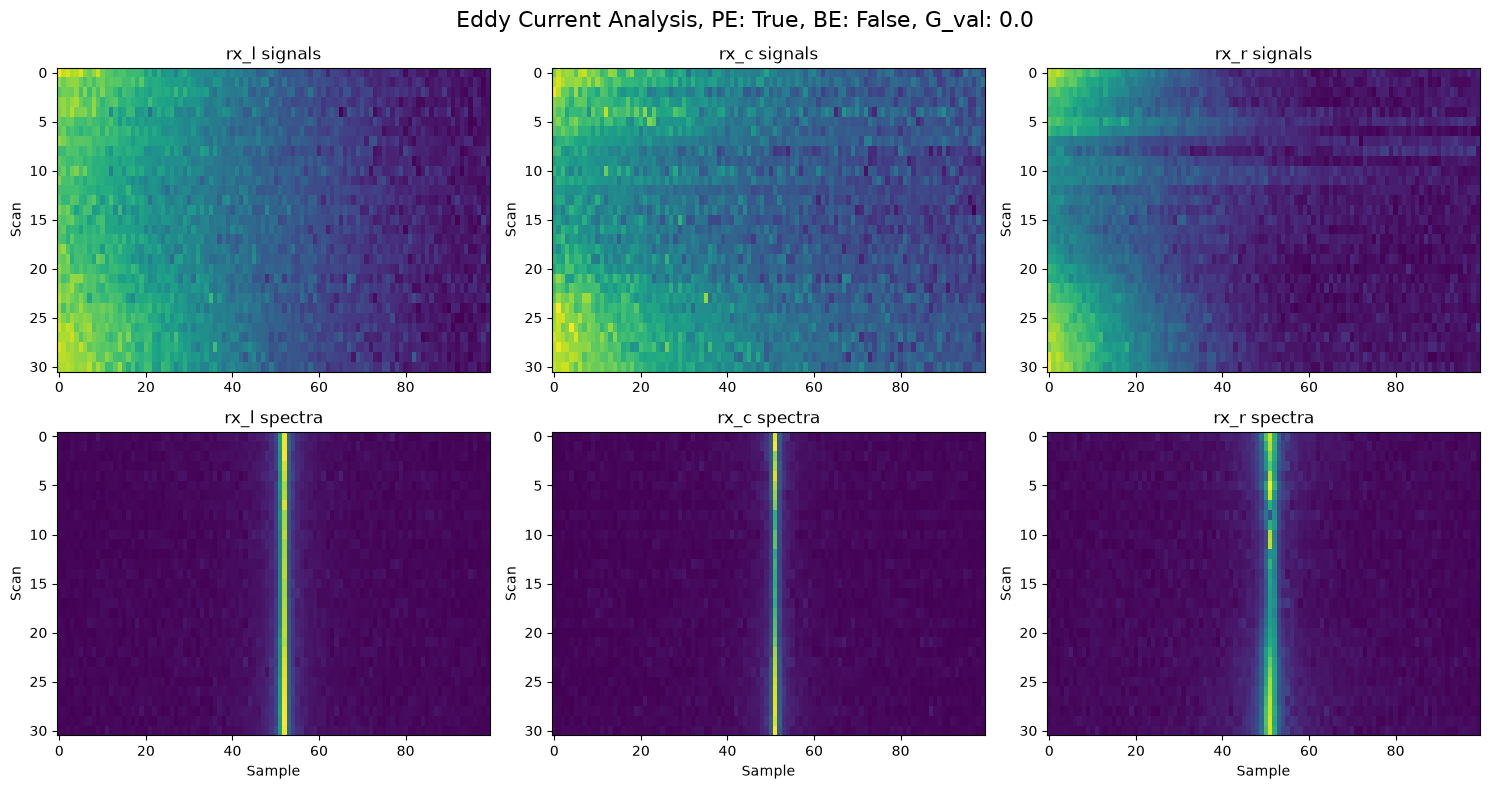

-12203.898050974507
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.08, 0.  , 0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


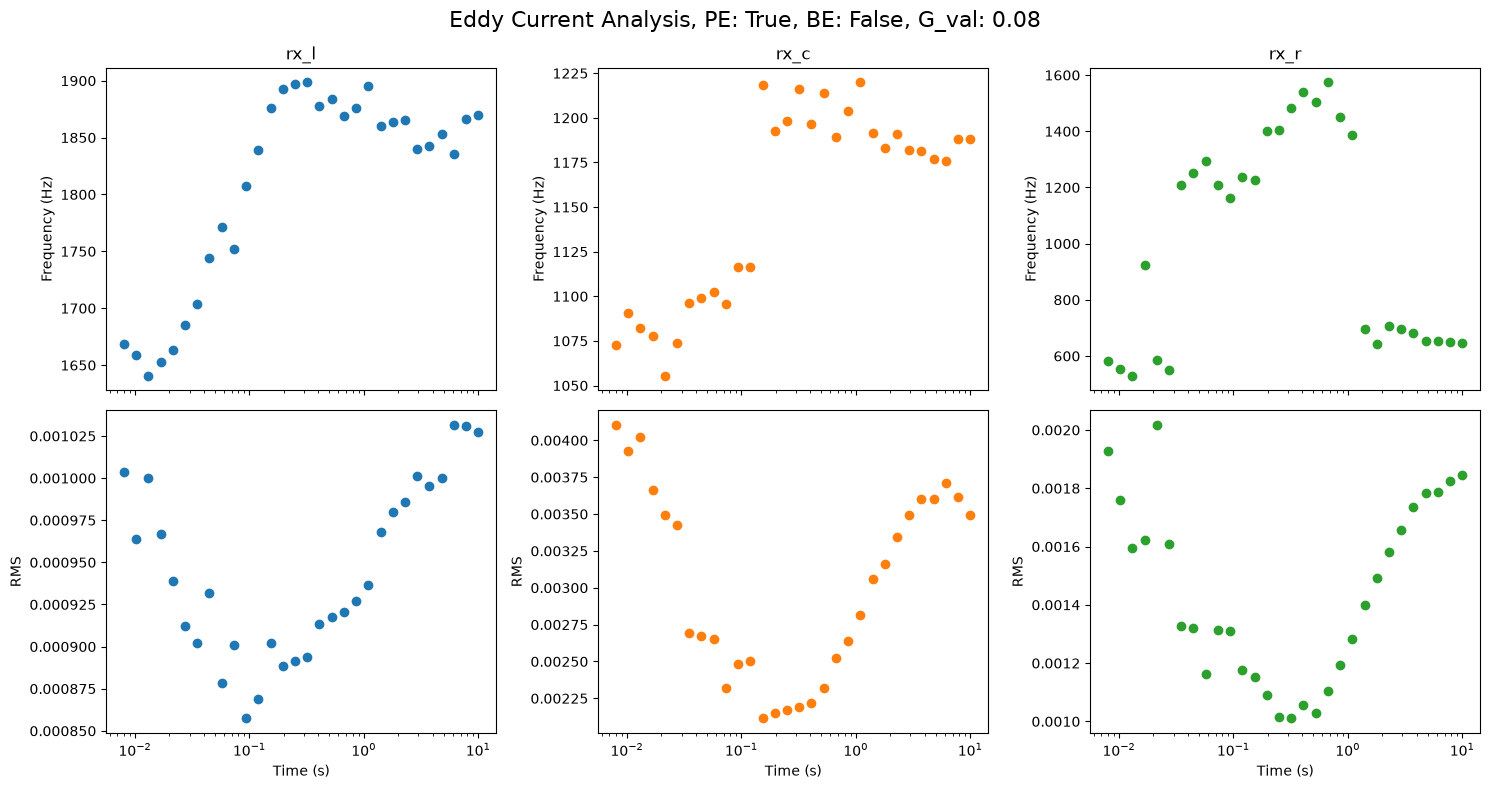

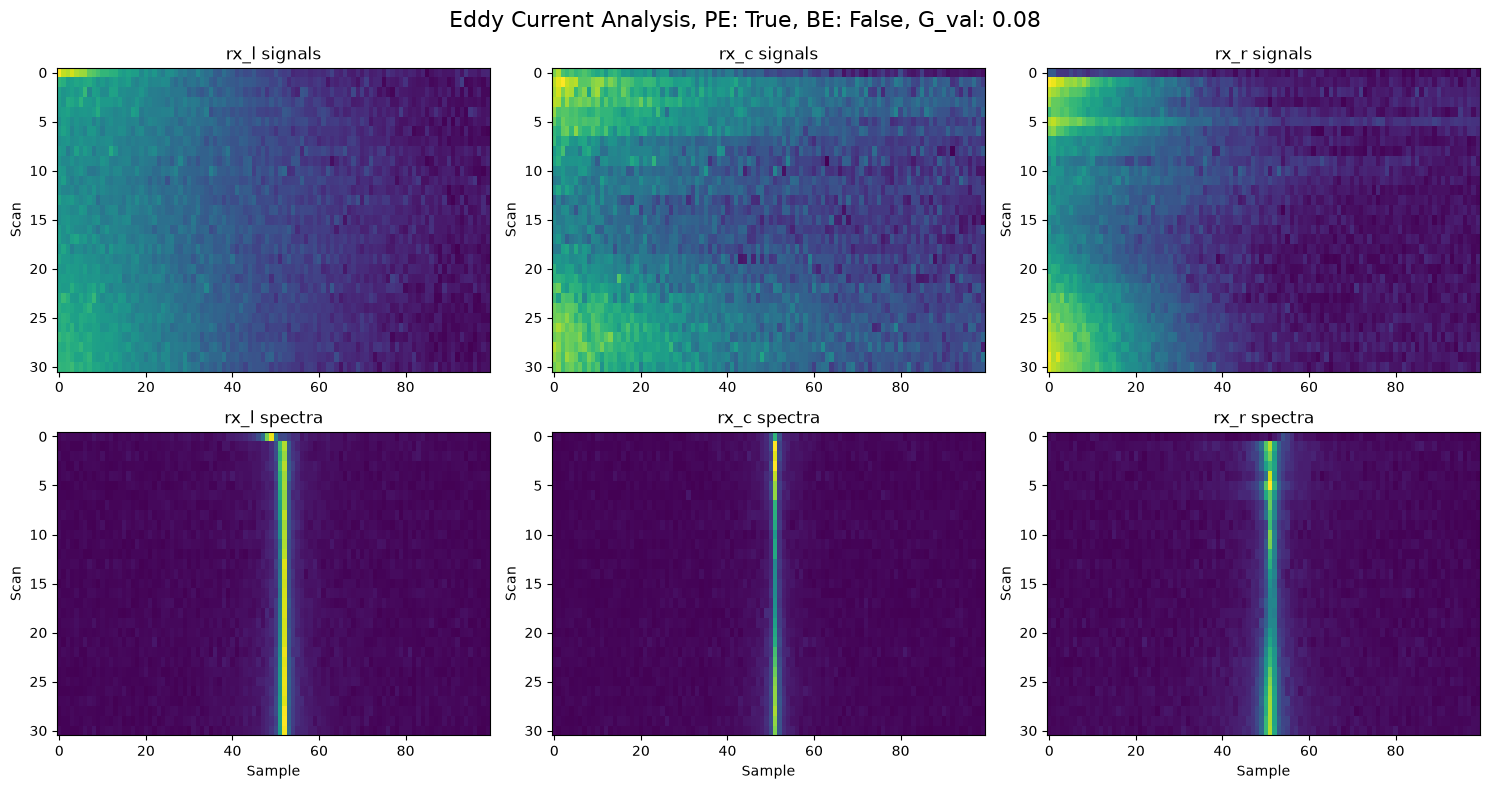

58020.98950524736
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.16, 0.  , 0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


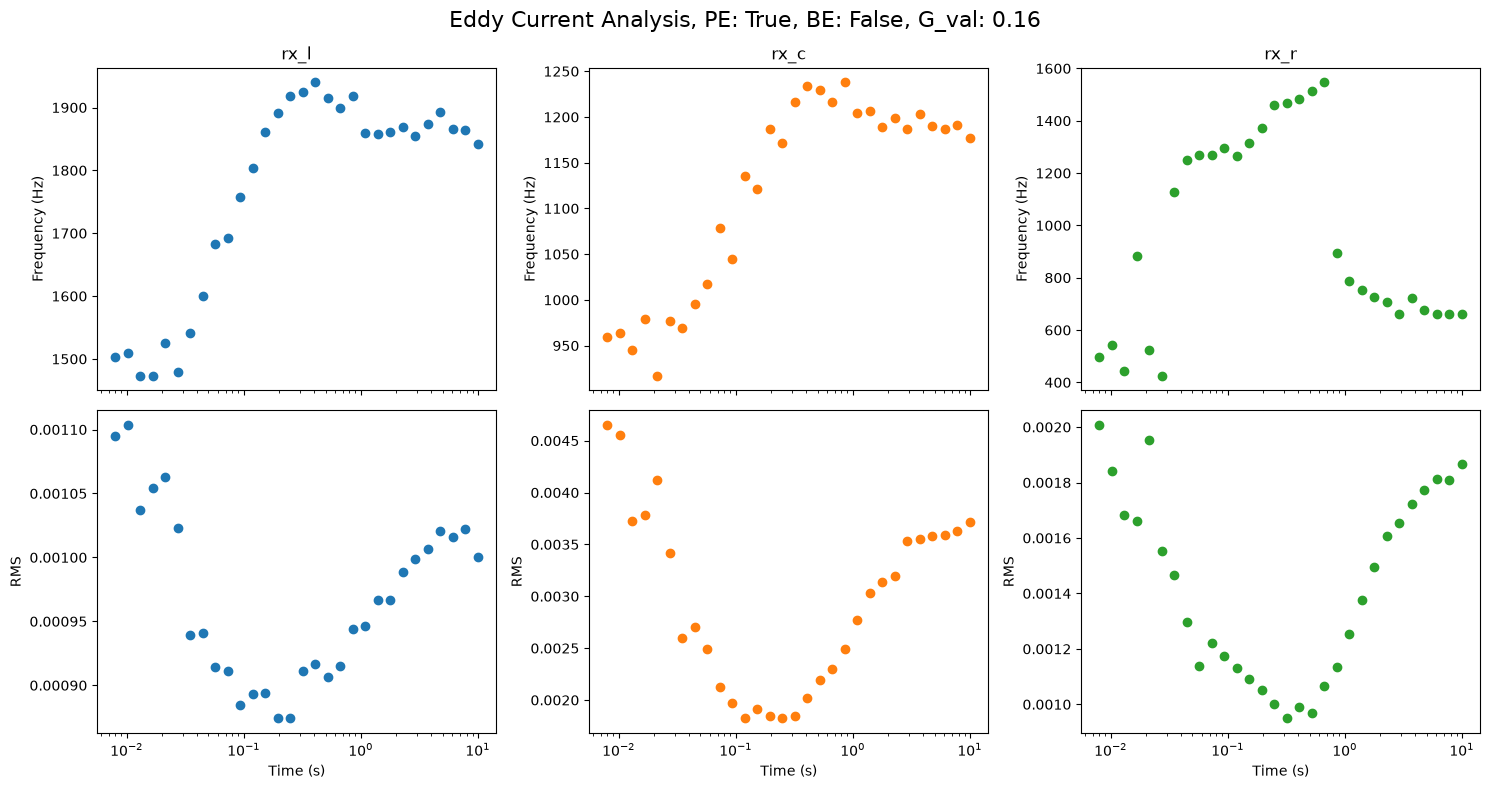

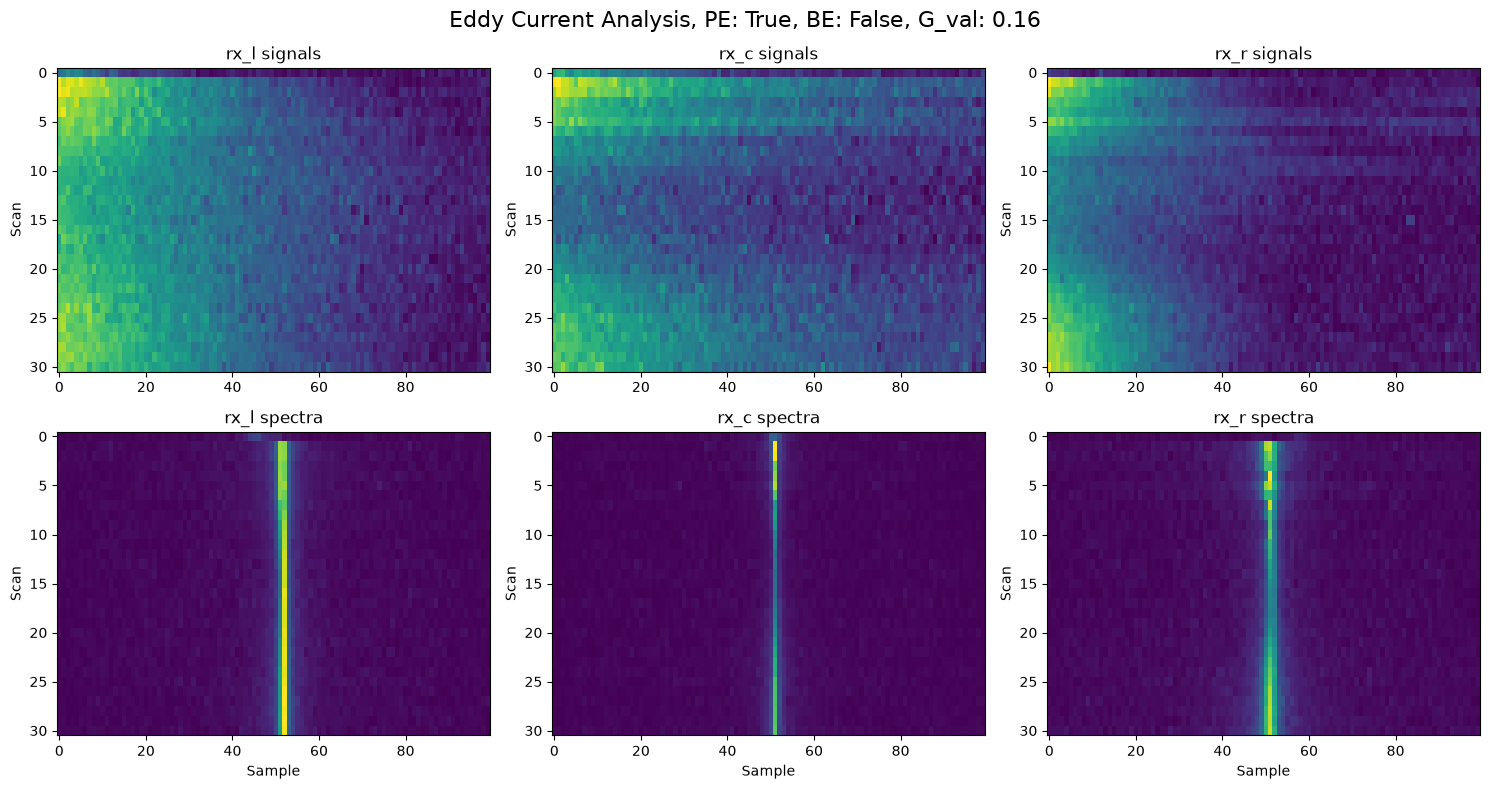

119150.42478760617
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.24, 0.  , 0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


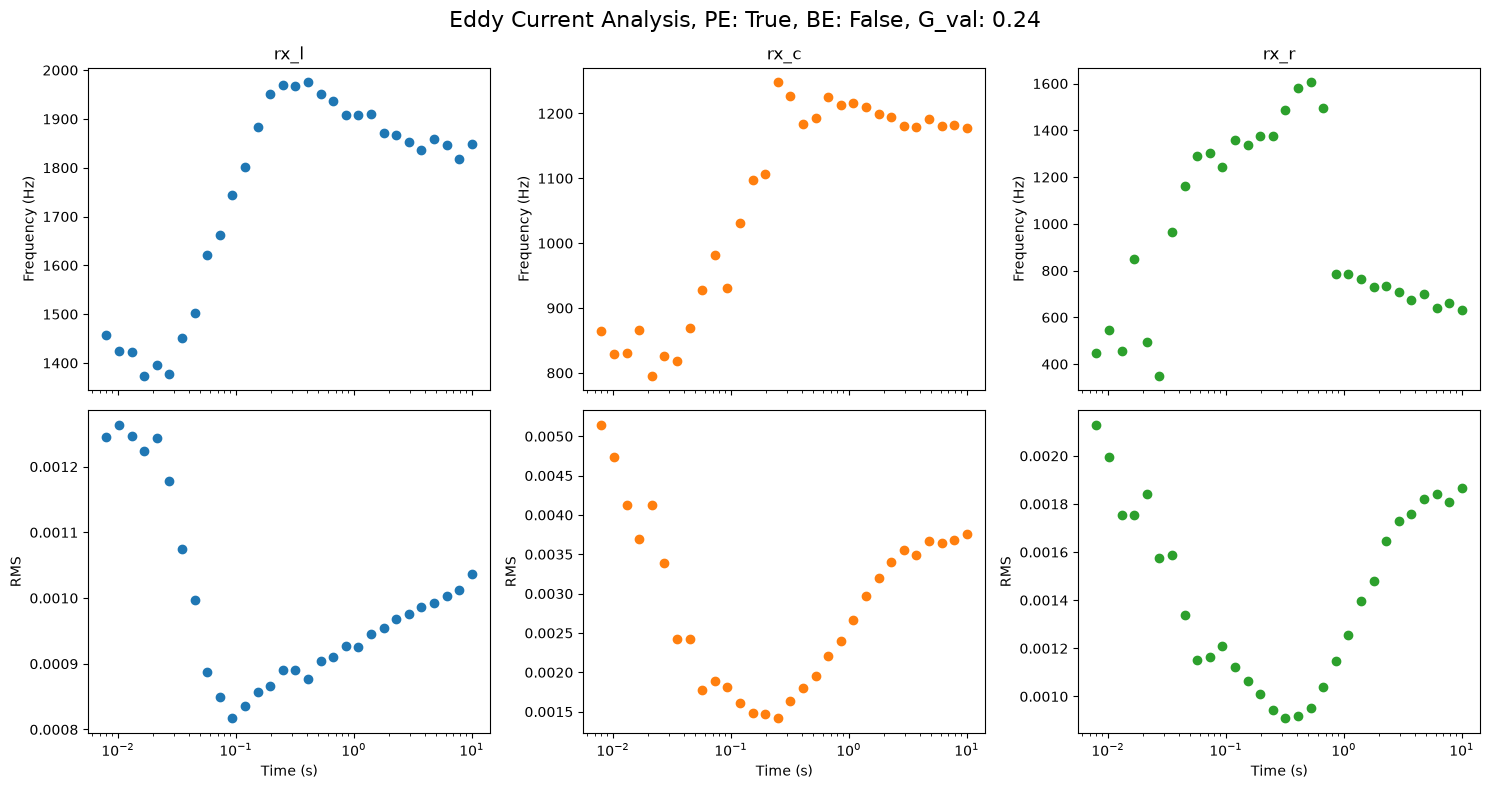

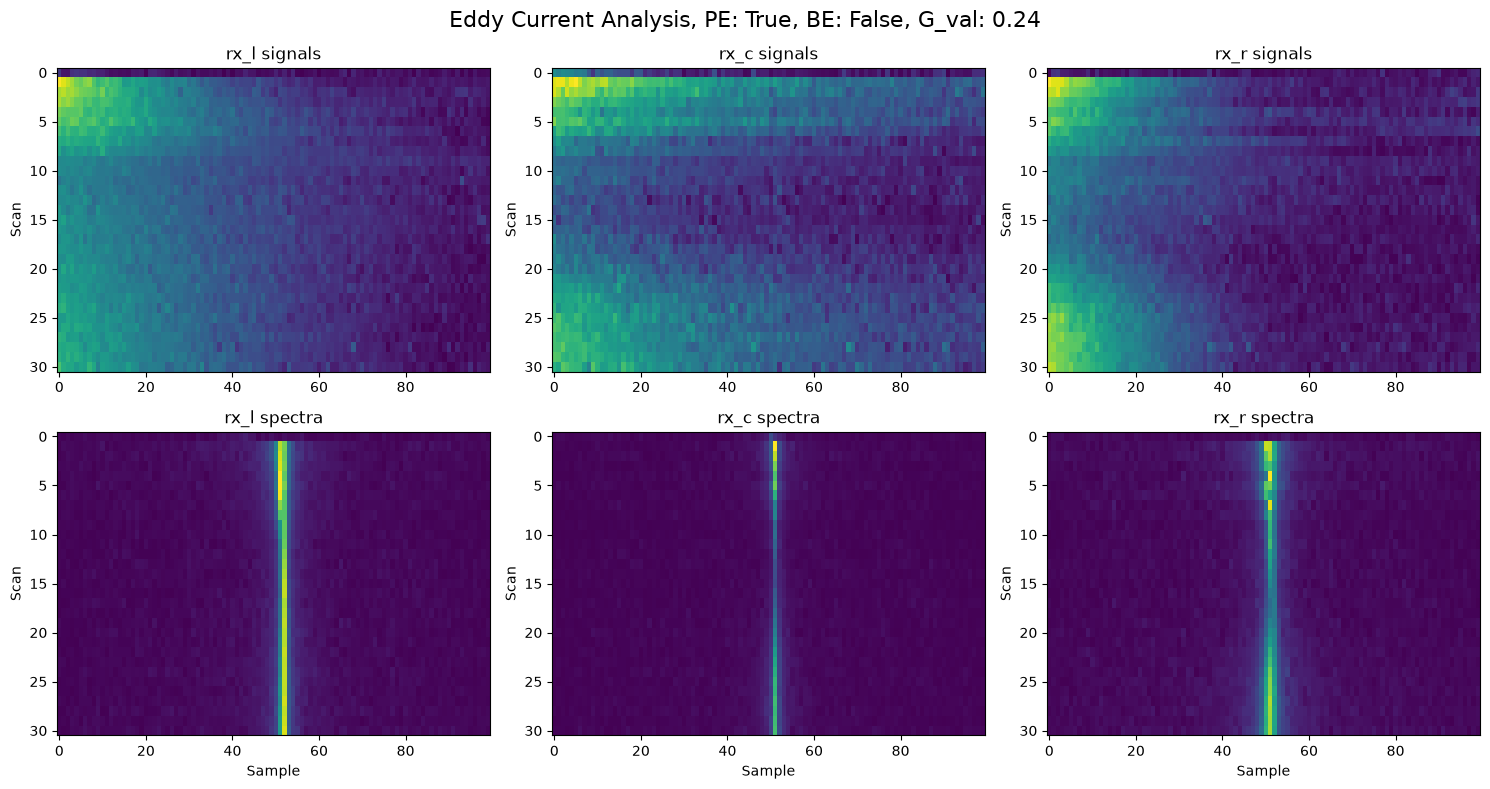

126936.5317341329
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.32, 0.  , 0.  ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


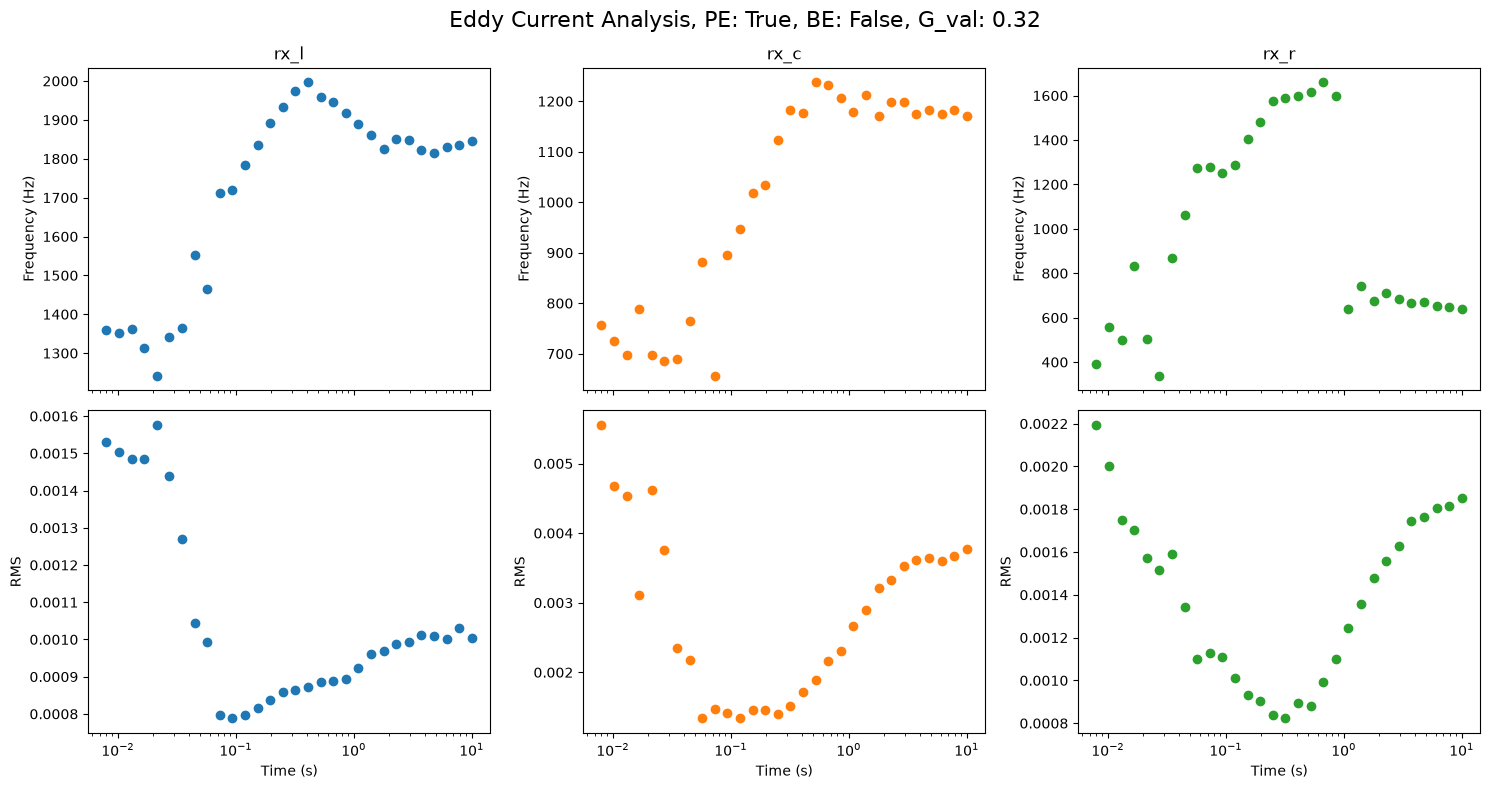

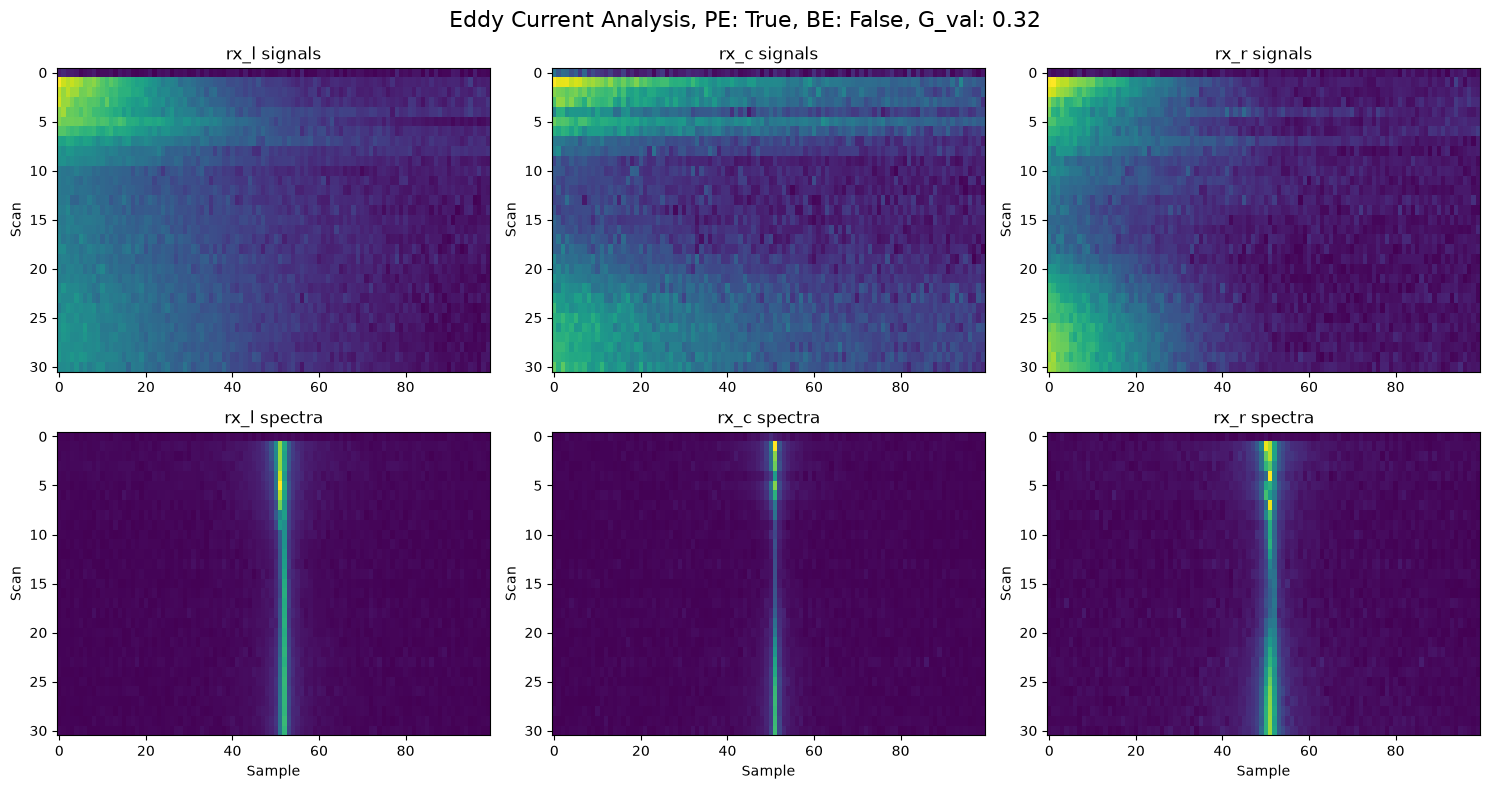

187696.1519240379
g_val doubled for X


ParameterSet(n_scans=1, f=63794600.0, a_pulse=0.049999999999999996, t_pulse=0.0006, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0.4, 0. , 0. ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=False, offsets=array([-0.01810526,  0.00151351,  0.00194595,  0.        ]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/', half_a=False)
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/notebooks/daisy/final_versions/globals/eddy_B0new.yaml


DEBUG:pe_eddy_edit:Pre-emphasis ON
DEBUG:pe_eddy_edit:B0 OFF


{'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066}
B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': -1261187.5744874568, 'Y': -1824422.2283394758, 'Z': -3258124.1274683066} {'X': 1155247.8538973178, 'Y': 1840362.3867826683, 'Z': 3091865.0605069515} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31


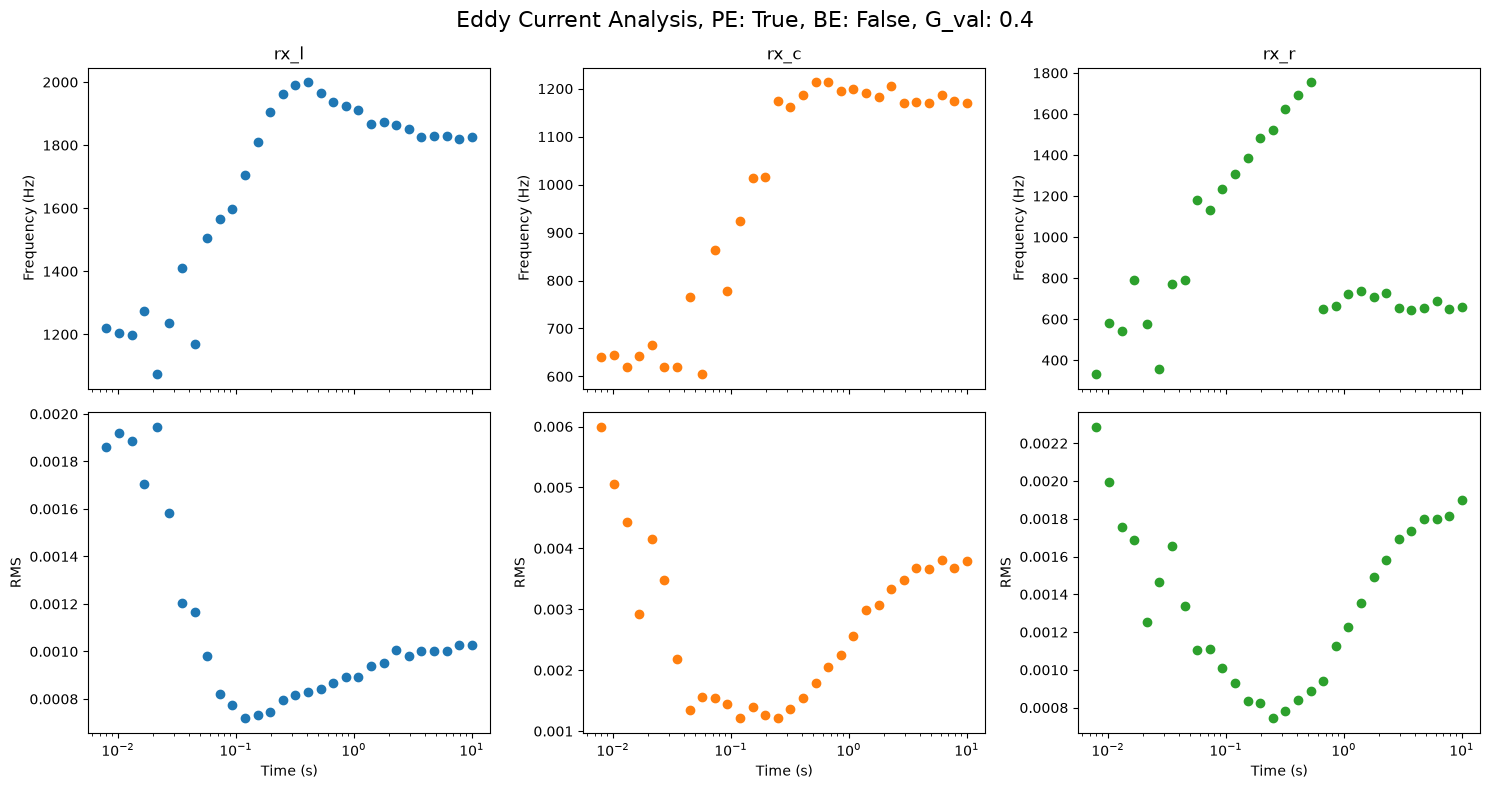

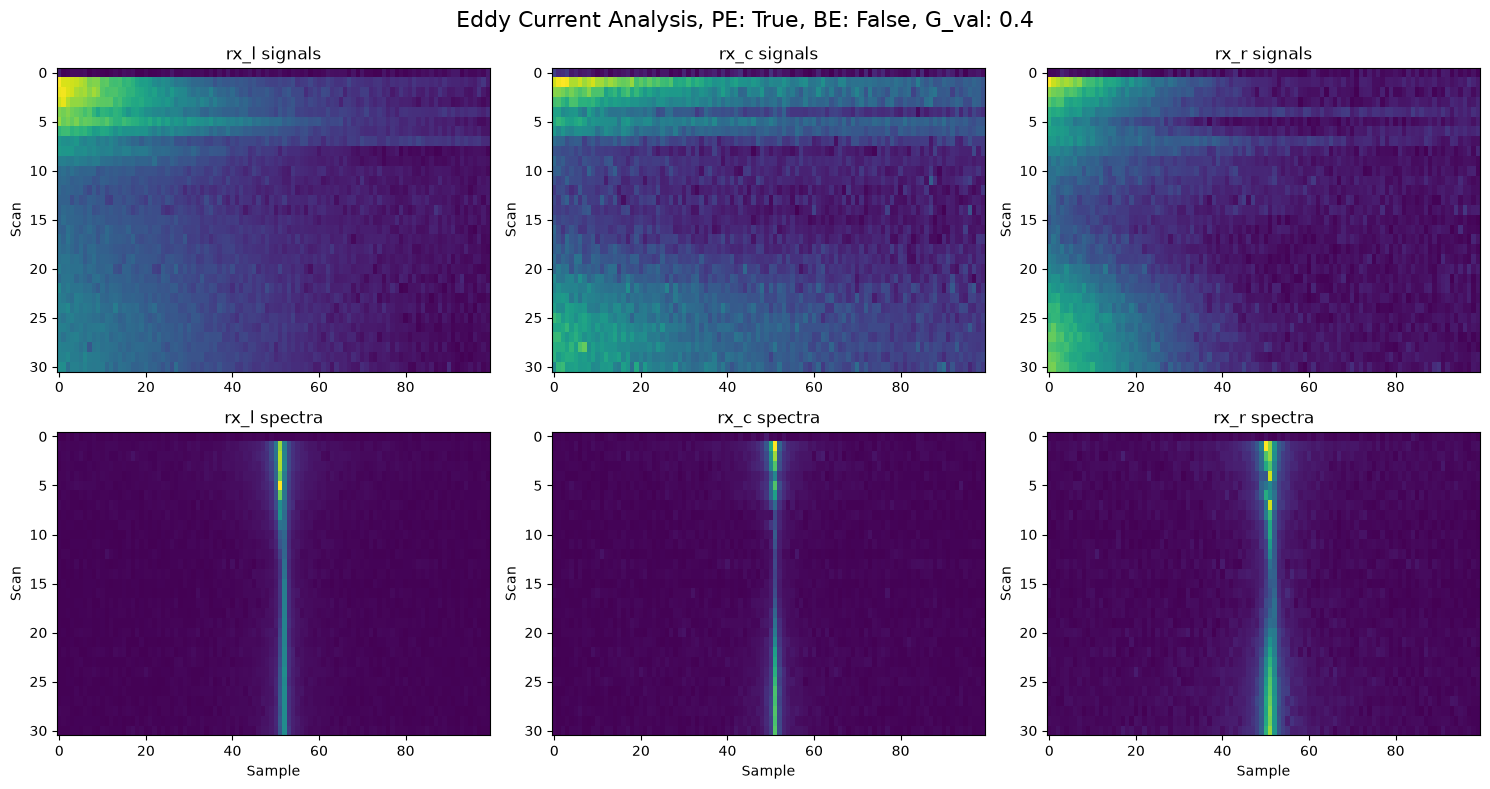

283673.1634182908


In [7]:
dict_ = {}


f_list = []

ZERO_FILLING = 200000
angle = 10 # flip angle used in the sequence
pe = [False, True]
be = [False]
# g_list = [0.05, 0.07, 0.1, 0.15, 0.20]
g_list = np.linspace(-0.2, 0.2, 11)
print("g_list:", g_list)
# g_list = [0.1, 0.15, 0.2, 0.25]
# distances of coils in meters
d_r = 5e-2
d_c = 0
d_l = -5e-2
name = "xgrad_xeddy"
axis = name[0].upper()

for e in pe:
    for b in be:
        for g_val in g_list:
            g_val = round(g_val, 2)
            seq = Sequence('pe_eddy_edit.py')
            
            # load relevant global variables
            seq.loadpar(GLOBALS_DIR+'frequency_tx0.yaml')
            seq.loadpar(GLOBALS_DIR+'shims.yaml')
            # g_val = 0.1
            
            if axis == "X":
                g_val = g_val*2
                print("g_val doubled for X")
        
            seq.setpar(
                n_scans = 1,
                # a_pulse=0.05555555555555555, 
                # t_pulse=0.0001,
                a_pulse = vals["a_90"]*(angle/90), 
                t_pulse = vals["t_90"],
                t_dw = 10e-6,
                n_samples = 100,
                t_acq_delay = 100e-6,
                t_grad = 10.0,
                t_ramp = 1e-3,
                t_wait = 8e-3,
                n_pulses = 30,
                t_end = 10.0, 
                t_next = 5, # wait between scans 
                # g_read = (0,0,g_val),
                # g_read = (0,g_val,0),
                g_read = (g_val,0,0),
                tx_chan = 0,
                rx_chan_list = (3,0,1),
                pre_emphasis = e,
                b0 = b,
                # half_a = half
                # file = GLOBALS_DIR,
            )
            
            pn.extension()
            print(seq.par)
            y = await seq.run()
        
            # REMAKING THE INDEXING OF THE ACQs
            times = np.geomspace(seq.par.t_wait, seq.par.t_end, num=seq.par.n_pulses)
        
            times = np.concatenate(([0], times))
            list_ = []
            n_acq = seq.par.n_pulses+1
            
            for i_pulse in range(n_acq):
                list_.append([(i_pulse+1 + n_acq * i_chan) for i_chan, rx in enumerate(seq.par.rx_chan_list)]) # +1 as started on 1 index not zero
            
            # print(list_)
            
            df_idx = pd.DataFrame(list_, columns = ["rx_l", "rx_c", "rx_r"])
            df_idx["times (s)"] = times
            # display(df_idx[0:3])
            apodization = 100
        
            df_freq = pd.DataFrame(df_idx["times (s)"], columns =["times (s)"]) # skip first one as is for gradient calibration
            df_rms = pd.DataFrame(df_idx["times (s)"],columns = ["times (s)"])
            
            # CALCULATING THE FREQ AND RMS
            for rx in df_idx.columns[0:3]: # dont do times column
                df = df_idx[rx]
                freq_c  = []
                rms_list  = []
                for key in df:        
                    t_dw = seq.par.t_dw
                    data = seq.data_map[key]
                    time = np.linspace(t_dw,len(data)*t_dw, len(data))
                    window = np.exp(-np.pi*apodization*time)
                    processed_signal = np.concatenate((seq.data_map[key]*window, np.zeros(ZERO_FILLING)))
                    freq, img = get_freq_spectrum(signal = processed_signal, dwell_time= seq.par.t_dw)
                        
                    RMS = np.sqrt(np.mean(np.abs(data)**2)) # plot this against time for each acq to see how the amplitude changes over time and checks that the flip angle leads to steady-state
                    
                    spectrum_mag = np.abs(img)
                    peak_index = np.argmax(spectrum_mag)
                    centre_freq = freq[peak_index]
                    freq_c.append(centre_freq)
                    rms_list.append(RMS)
                    
                df_freq[rx] = freq_c
                df_rms[rx] = rms_list
        
            # PLOTTING TO SHOW THE FREQ AND RMS
            fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
            
            cols = ["rx_l", "rx_c", "rx_r"]
            colors = {
                "rx_l": "tab:blue",
                "rx_c": "tab:orange",
                "rx_r": "tab:green",
            }
            
            for i, col in enumerate(cols):
            
                # Frequency row
                axes[0, i].scatter(
                    df_freq["times (s)"][1:],
                    df_freq[col][1:],
                    color=colors[col]
                )
                axes[0, i].set_xscale("log")
                axes[0, i].set_title(col)
                axes[0, i].set_ylabel("Frequency (Hz)")
            
                # RMS row
                
                axes[1, i].scatter(df_rms["times (s)"][1:], df_rms[col][1:], color=colors[col])
                axes[1, i].set_xscale("log")
                axes[1, i].set_xlabel("Time (s)")
                axes[1, i].set_ylabel("RMS")
        
            # fig.suptitle(f"Eddy Current Analysis, PE: {e}, BE: {b}, Half: {half}", fontsize=16)
            fig.suptitle(f"Eddy Current Analysis, PE: {e}, BE: {b}, G_val: {g_val}", fontsize=16)
            plt.tight_layout()
            plt.show()
        
            fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=False)
        
            cols = ["rx_l", "rx_c", "rx_r"]
            
            for i, col in enumerate(cols):
            
                df = df_idx[col]
            
                signals = []
                spectra = []
            
                for key in df:
                    signal = seq.data_map[key]
            
                    freq, spectrum = get_freq_spectrum(signal=signal,dwell_time=seq.par.t_dw)
            
                    signals.append(signal)
                    spectra.append(spectrum)
            
                signals = np.array(signals)
                spectra = np.array(spectra)
            
                axes[0, i].imshow(np.abs(signals),aspect="auto",cmap="viridis")
                axes[0, i].set_title(f"{col} signals")
                axes[0, i].set_ylabel("Scan")
            
                axes[1, i].imshow(np.abs(spectra),aspect="auto",cmap="viridis")
                axes[1, i].set_title(f"{col} spectra")
                axes[1, i].set_ylabel("Scan")
                axes[1, i].set_xlabel("Sample")
            # fig.suptitle(f"Eddy Current Analysis, PE: {e}, BE: {b}, Half: {half}", fontsize=16)
            fig.suptitle(f"Eddy Current Analysis, PE: {e}, BE: {b}, G_val: {g_val}", fontsize=16)
        
            plt.tight_layout()
            plt.show()
        
        
            g_hzpm = (df_freq["rx_r"][0] - df_freq["rx_l"][0]) / (d_r - d_l)
            print(g_hzpm)
            
            df_freq["g_eddy"] = (df_freq["rx_r"] - df_freq["rx_l"]) / (d_r - d_l)
            df_freq["E(t)"] = df_freq["g_eddy"]/ g_hzpm 
            
            df_freq["B0(t)"] = df_freq["rx_c"]/ g_hzpm
        
            f_list.append(df_freq)
    
            key = f"{name}_PE{e}_BE{b}_G{g_val}"

            dict_[key] = {
                "freq": df_freq.copy(),
                "rms": df_rms.copy(),
                "g_hzpm": g_hzpm,
            }


### Plot the E(t)

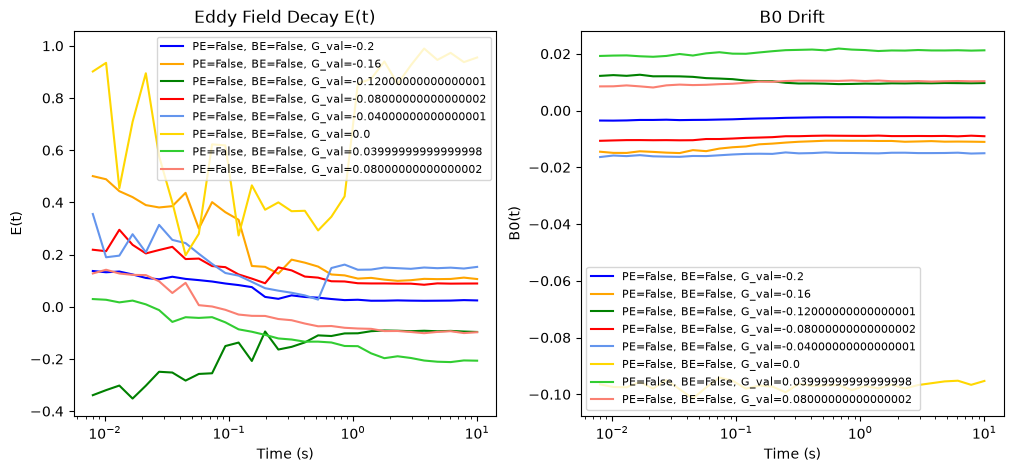

<Figure size 640x480 with 0 Axes>

In [8]:
       
labels = []

for e in pe:
    for b in be:
        for g_val in g_list:
            labels.append(f"PE={e}, BE={b}, G_val={g_val}")
            
# colours = [ "blue", "cornflowerblue", "orange", "gold", "green", "limegreen", "red", "salmon"]
colours = [
    "blue", 
    "orange", 
    "green", 
    "red", "cornflowerblue","gold", "limegreen","salmon",

]
# colours = [ "blue", "red"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig2 = plt.figure()

for df, label, colour in zip(f_list, labels, colours):
    if "PE=True" in label:
        axes[0].plot(df["times (s)"][1:], df["E(t)"][1:], label=label, color=colour, linestyle = "--")

    else:
        axes[0].plot(df["times (s)"][1:], df["E(t)"][1:], label=label, color=colour)

axes[0].set_xscale("log")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("E(t)")
axes[0].set_title("Eddy Field Decay E(t)")
axes[0].legend(fontsize=8)

for df, label, colour in zip(f_list, labels, colours):
    # if colour not in ["red", "green"]:
    axes[1].plot(df["times (s)"][1:], df["B0(t)"][1:], label=label, color=colour)

axes[1].set_xscale("log")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("B0(t)")
axes[1].set_title("B0 Drift")
axes[1].legend(fontsize=8)

plt.suptitle(name)
plt.tight_layout()
plt.show() 

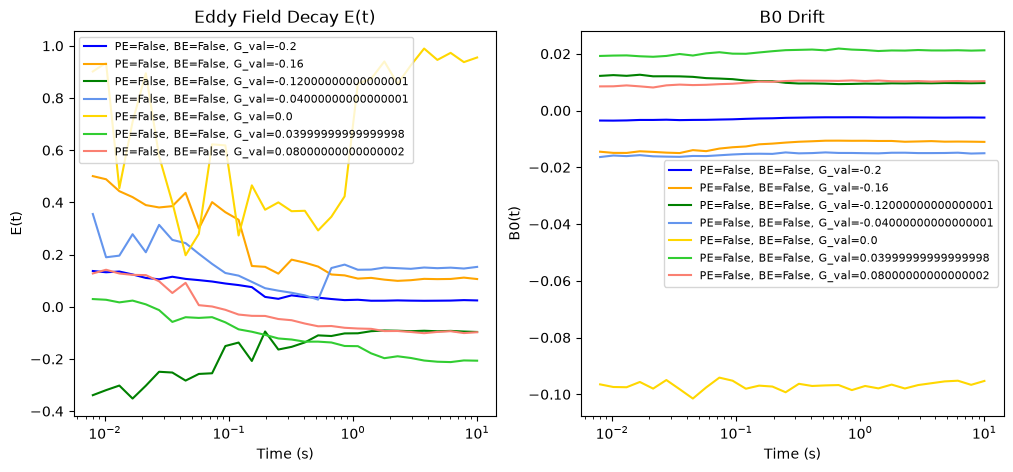

<Figure size 640x480 with 0 Axes>

In [9]:
labels = []

for e in pe:
    for b in be:
        for g_val in g_list:
            labels.append(f"PE={e}, BE={b}, G_val={g_val}")
            
# colours = [ "blue", "cornflowerblue", "orange", "gold", "green", "limegreen", "red", "salmon"]
colours = [
    "blue", 
    "orange", 
    "green", 
    "red", "cornflowerblue","gold", "limegreen","salmon",

]
colours_list = ["red"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig2 = plt.figure()

for df, label, colour in zip(f_list, labels, colours):
    if colour not in colours_list:
        axes[0].plot(df["times (s)"][1:], df["E(t)"][1:], label=label, color=colour)

axes[0].set_xscale("log")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("E(t)")
axes[0].set_title("Eddy Field Decay E(t)")
axes[0].legend(fontsize=8)

for df, label, colour in zip(f_list, labels, colours):
    if colour not in colours_list:
        axes[1].plot(df["times (s)"][1:], df["B0(t)"][1:], label=label, color=colour)

axes[1].set_xscale("log")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("B0(t)")
axes[1].set_title("B0 Drift")
axes[1].legend(fontsize=8)

plt.suptitle(name)
plt.tight_layout()
plt.show() 

In [10]:
g_h = []
g_vals = []
pe_vals = []
import re

for key, value in dict_.items():

    match = re.search(r'G(-?\d*\.?\d+)$', key)
    if match is None:
        continue

    g = float(match.group(1))
    g_vals.append(g)
    g_h.append(dict_[key]["g_hzpm"])
    pe_vals.append("PETrue" in key)
    print(key, ": ", dict_[key]["g_hzpm"])

df_ghzpm = pd.DataFrame({"G": g_vals, "g_hzpm (Hz/m)": g_h, "PE": pe_vals,})

xgrad_xeddy_PEFalse_BEFalse_G-0.4 :  -487151.424287856
xgrad_xeddy_PEFalse_BEFalse_G-0.32 :  -109405.2973513243
xgrad_xeddy_PEFalse_BEFalse_G-0.24 :  124342.82858570712
xgrad_xeddy_PEFalse_BEFalse_G-0.16 :  -132928.5357321339
xgrad_xeddy_PEFalse_BEFalse_G-0.08 :  -79700.14992503745
xgrad_xeddy_PEFalse_BEFalse_G0.0 :  -12403.79810094952
xgrad_xeddy_PEFalse_BEFalse_G0.08 :  56941.529235382295
xgrad_xeddy_PEFalse_BEFalse_G0.16 :  117426.28685657168
xgrad_xeddy_PEFalse_BEFalse_G0.24 :  202918.54072963513
xgrad_xeddy_PEFalse_BEFalse_G0.32 :  140444.77761119438
xgrad_xeddy_PEFalse_BEFalse_G0.4 :  214202.89855072458
xgrad_xeddy_PETrue_BEFalse_G-0.4 :  -267996.00199900044
xgrad_xeddy_PETrue_BEFalse_G-0.32 :  -154152.92353823085
xgrad_xeddy_PETrue_BEFalse_G-0.24 :  -154962.51874062966
xgrad_xeddy_PETrue_BEFalse_G-0.16 :  -133363.31834082954
xgrad_xeddy_PETrue_BEFalse_G-0.08 :  -71604.19790104945
xgrad_xeddy_PETrue_BEFalse_G0.0 :  -12203.898050974507
xgrad_xeddy_PETrue_BEFalse_G0.08 :  58020.989

In [11]:
import pickle


dict_["df_ghzpm"] = df_ghzpm
with open(f"{name}_2.pkl", "wb") as f:
    pickle.dump(dict_, f)


## Plot the G Calibration Vs Grad val

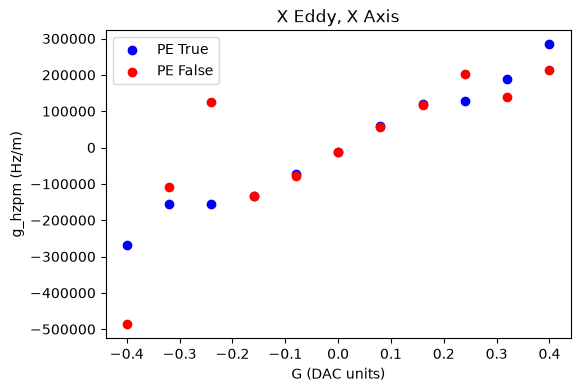

In [12]:

mask = np.array(pe_vals) # mask for PE on or off

plt.figure(figsize=(6,4))
plt.scatter(np.array(g_vals)[mask], np.array(g_h)[mask], color="blue", label="PE True")
plt.scatter(np.array(g_vals)[~mask], np.array(g_h)[~mask], color="red", label="PE False")

plt.xlabel("G (DAC units)")
plt.ylabel("g_hzpm (Hz/m)")
plt.title("X Eddy, X Axis")
plt.legend()
plt.show()

Slope: 832083.9580209893
Intercept: 0.0


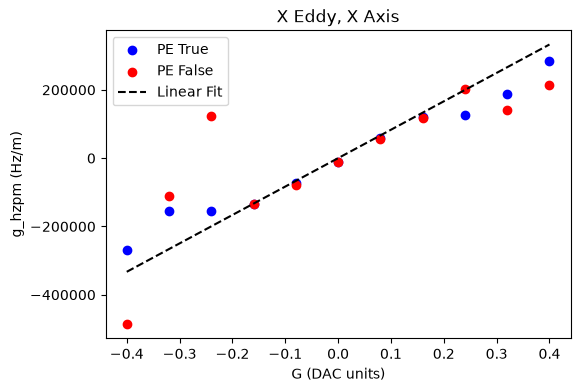

In [17]:
from sklearn.linear_model import LinearRegression

val1 = -0.15
val2 = 0.15
df_fit = df_ghzpm[(df_ghzpm["G"] > val1) & (df_ghzpm["G"] < val2)]
# df_fit = df_ghzpm
X = df_fit[["G"]]
Y = df_fit["g_hzpm (Hz/m)"]

# Force intercept to 0 by setting fit_intercept=False
model = LinearRegression(fit_intercept=False)
model.fit(X, Y)

# Get the slope
slope = model.coef_[0]

print(f"Slope: {slope}")           # e.g., ~2.0
print(f"Intercept: {model.intercept_}") # Strictly 0.0

x_fit = np.linspace(df_ghzpm["G"].min(), df_ghzpm["G"].max(), 100)


mask = np.array(pe_vals) # mask for PE on or off

plt.figure(figsize=(6,4))
plt.scatter(np.array(g_vals)[mask], np.array(g_h)[mask], color="blue", label="PE True")
plt.scatter(np.array(g_vals)[~mask], np.array(g_h)[~mask], color="red", label="PE False")
plt.plot(x_fit, slope*x_fit, 'k--', label=f"Linear Fit")
# plt.plot(x_fit, slope*x_fit, 'k--', color = "orange", label=f"Linear Fit")

plt.xlabel("G (DAC units)")
plt.ylabel("g_hzpm (Hz/m)")
plt.title("X Eddy, X Axis")
plt.legend()
plt.show()

## Load into YAML

In [18]:
import yaml
# notebooks/daisy/kahu_eddy/pre_emph_eddy/inv_laplace/g_hzpm_slope.yaml
with open("g_hzpm_slope.yaml", "r") as f:
    data = yaml.safe_load(f)
    print(data)

data[axis] = float(slope)  # new value

with open("g_hzpm_slope.yaml", "w") as f:
    print(data)
    yaml.safe_dump(data, f, sort_keys=False)

{'X': 832083.9580209893, 'Y': 1415821.8509792718, 'Z': 1159804.026558149}
{'X': 832083.9580209893, 'Y': 1415821.8509792718, 'Z': 1159804.026558149}
